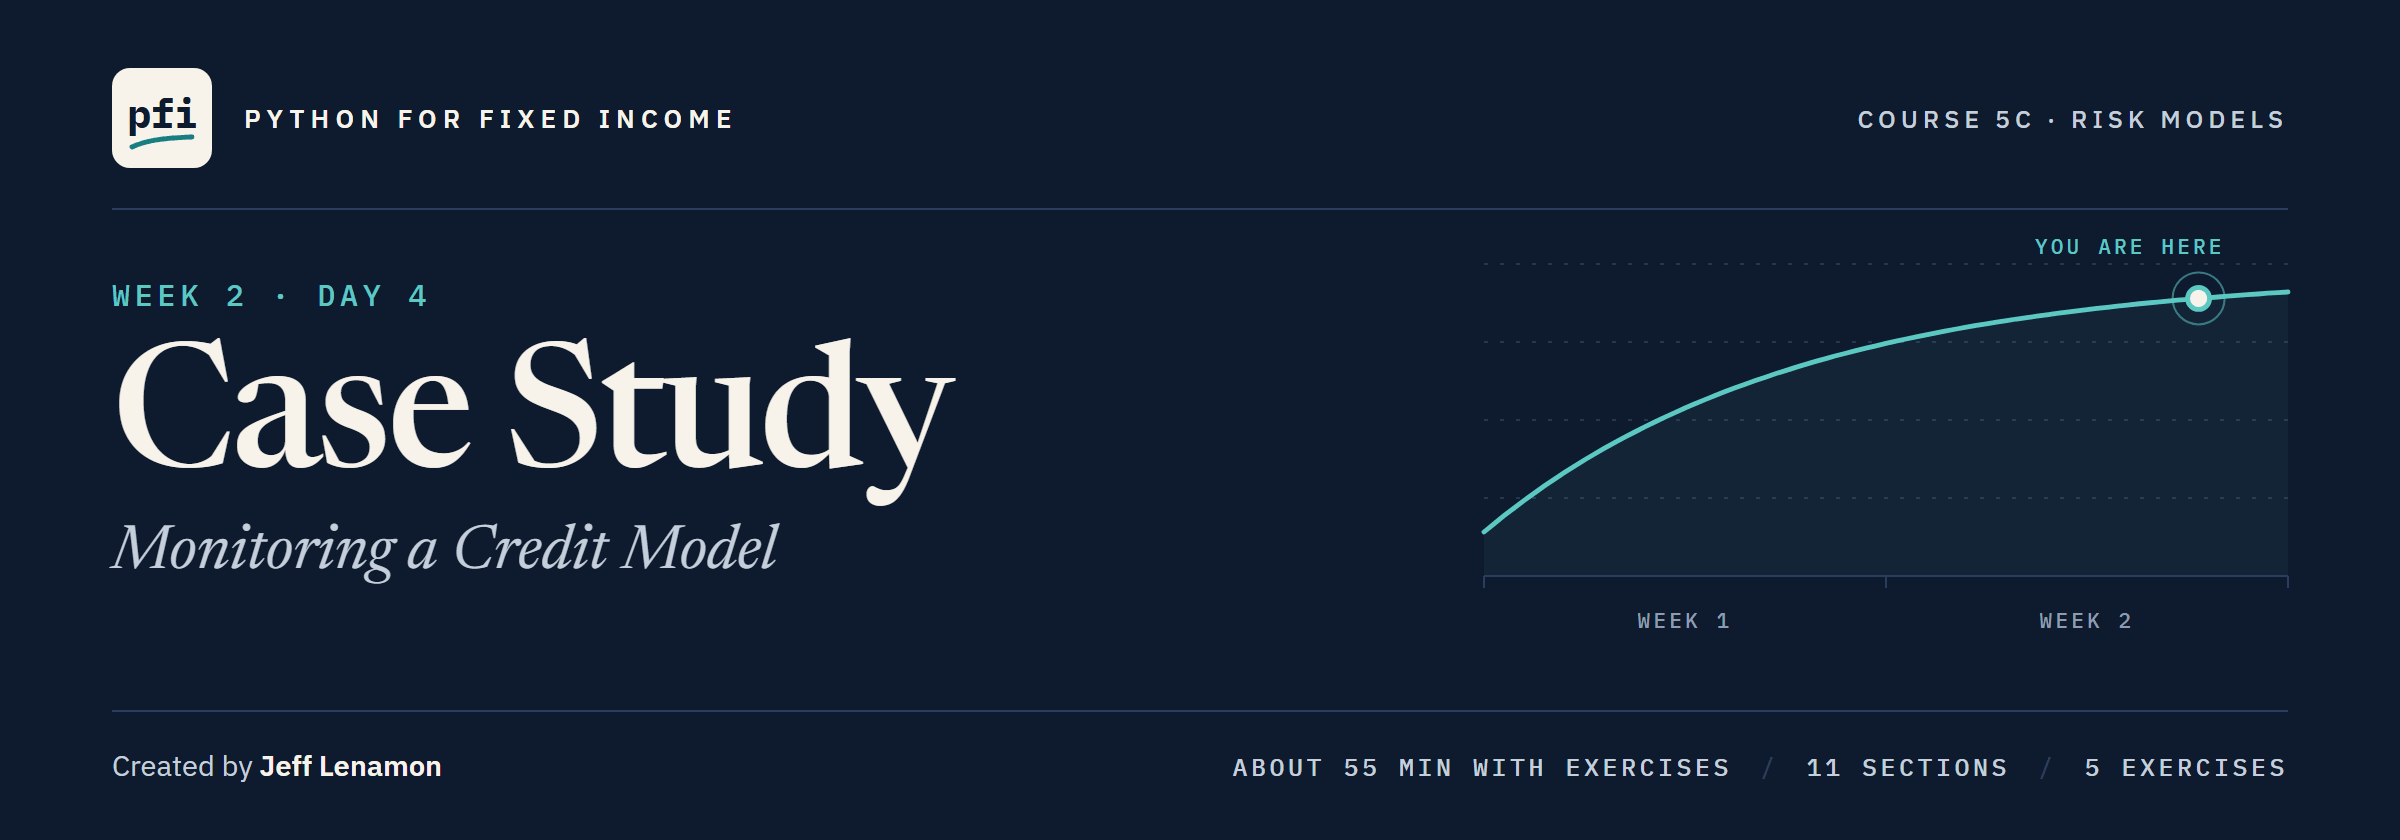

# Case Study: Monitoring a Credit Model

Week 2, Day 4. Freeze a hazard model on the reference years, then watch the years after with input checks, outcome checks and one report a year.

**Data:** `course5c_cohort.csv`, 4,000 invented firms followed year by year over 20 study years to default, exit, or the end: **synthetic**, ids only, no calendar years, and no agency default statistic.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day4/09_case_study_monitoring_a_credit_model.ipynb)

# Problem Statement

## Business Context

Day 5's discrete-time hazard was frozen at the end of study year 10: fitted on study years 1 to 10, its five coefficients fixed.
Since then it has scored every firm-year of study years 11 to 14.
Today the risk team builds its monitor: which checks, when each can run, against what reference, and with which bands.
Then a colleague asks for two case studies: the firms that entered after the freeze, and a copy whose ratings are shuffled within each year.
A status describes a past study year of these invented firms, never what the model will do.

## Objectives

Freeze a model on reference years and score later years with it.
Check a year's ranking and level against its outcomes, and set a count beside its Poisson range.
Measure the drift of a score and its inputs with PSI, and flag unusual inputs with the robust rule.
Separate the stock of firm-years from the flow of new firms.
Write a monitoring report with stated bands, and read it on a subgroup and on a planted copy.
Compare a frozen model with one refitted each year.

## Data Dictionary

`course5c_cohort.csv`, one row per firm per study year (the columns used today):

1. `firm_id`: the firm, an invented id
2. `study_year`: 1 to 20, never a calendar year; today reads 1 to 14
3. `years_since_entry`: 1 in the firm's first year
4. `rating_score`: 1 (AAA) to 18 (CCC)
5. `leverage`: debt to EBITDA, times
6. `coverage`: EBITDA to interest, times
7. `default`: 1 in the year the firm defaulted

`sector`, `rating` and `exit` are not read today.

Made here: Day 5's `log_coverage` and `early_years`, `entry_year`, `after_freeze`, `fitted` (the model's default probability for that firm-year), `EDGES`, the reports, `new_firms`, `shuffled` and `planted`.

## Your Route Through Day 4

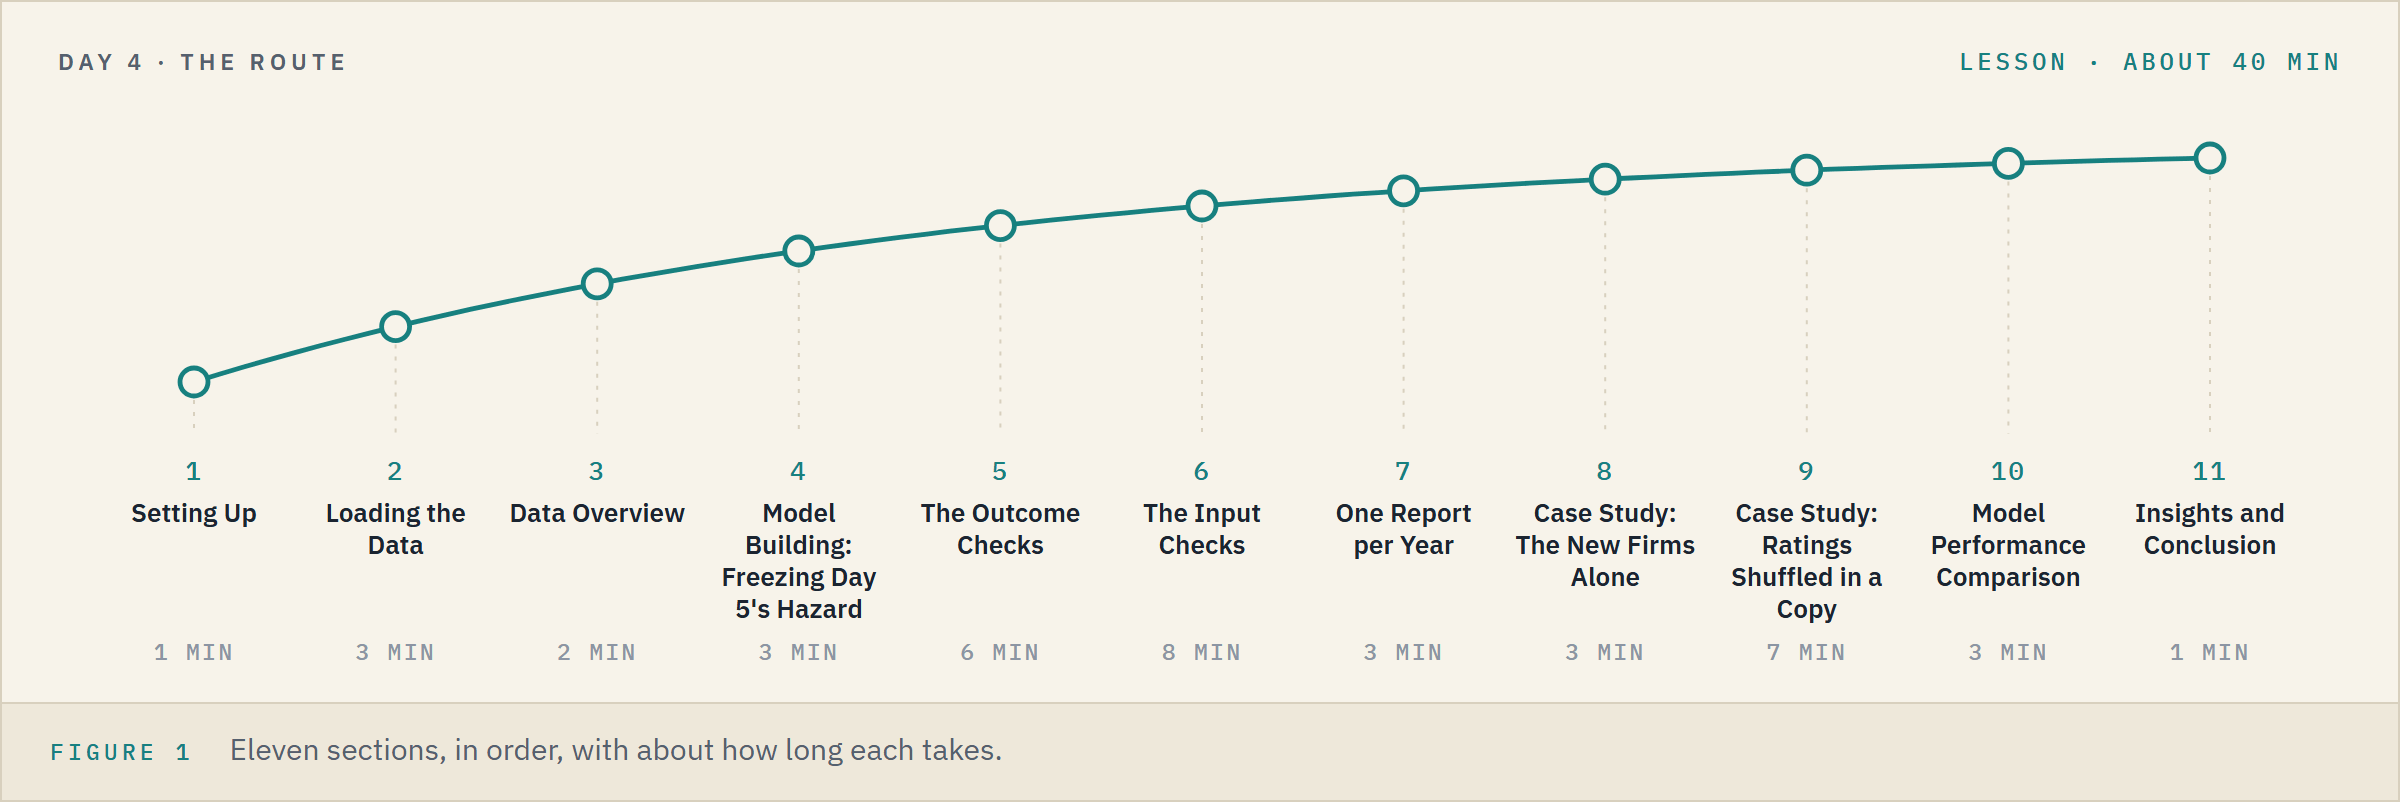

**Time.** About 40 minutes for the lesson, then about 15 for the five exercises.

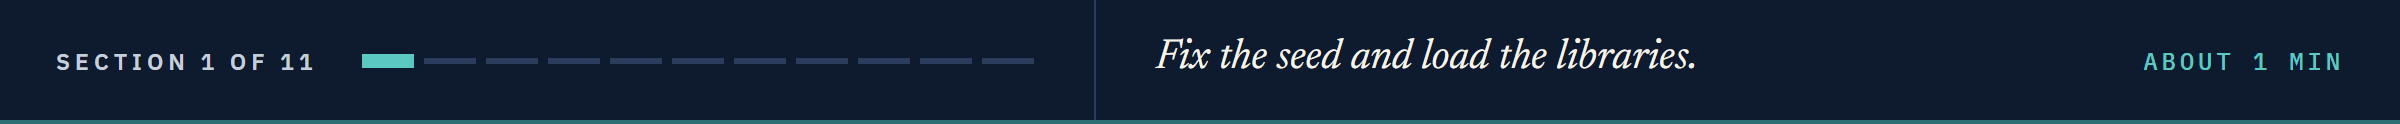

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# the Poisson distribution, the logistic fit, and the AUC (Course 4's Day 8)
from scipy import stats
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

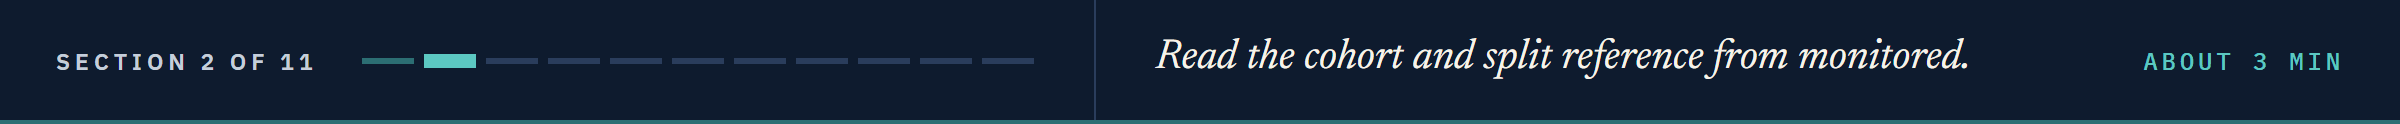

# Loading the Data

## Reading the Development Years

In [3]:
# the synthetic cohort, and Day 3's split: development study years 1 to 14; the later years are counted and left alone
cohort = pd.read_csv(DATA + "course5c_cohort.csv")
DEVELOPMENT_END = 14
development = cohort[cohort["study_year"] <= DEVELOPMENT_END].copy()
print("Development firm-years:", len(development), "| firms:", development["firm_id"].nunique(), "| defaults:", development["default"].sum())
print("Held-out firm-years:", len(cohort) - len(development))

Development firm-years: 18503 | firms: 3504 | defaults: 345
Held-out firm-years: 11112


## Day 5's Features

In [4]:
# Day 5's two features, and the four the model reads
development["log_coverage"] = np.log(development["coverage"])
development["early_years"] = development["years_since_entry"].between(2, 4).astype(int)
FEATURES = ["rating_score", "leverage", "log_coverage", "early_years"]

## The Reference and the Monitored Years

**Monitoring** watches a model after it is fixed.
The **reference years** are the rows it was fitted on, study years 1 to 10.
The **monitored years**, 11 to 14, are scored by it and checked against the reference.

In [5]:
# the frozen fit's last study year, then the reference rows and the monitored rows
FIT_END = 10
in_reference = development["study_year"] <= FIT_END
print("Reference firm-years:", in_reference.sum(), "| defaults:", development.loc[in_reference, "default"].sum())
print("Monitored firm-years:", (~in_reference).sum())

Reference firm-years: 10705 | defaults: 217
Monitored firm-years: 7798


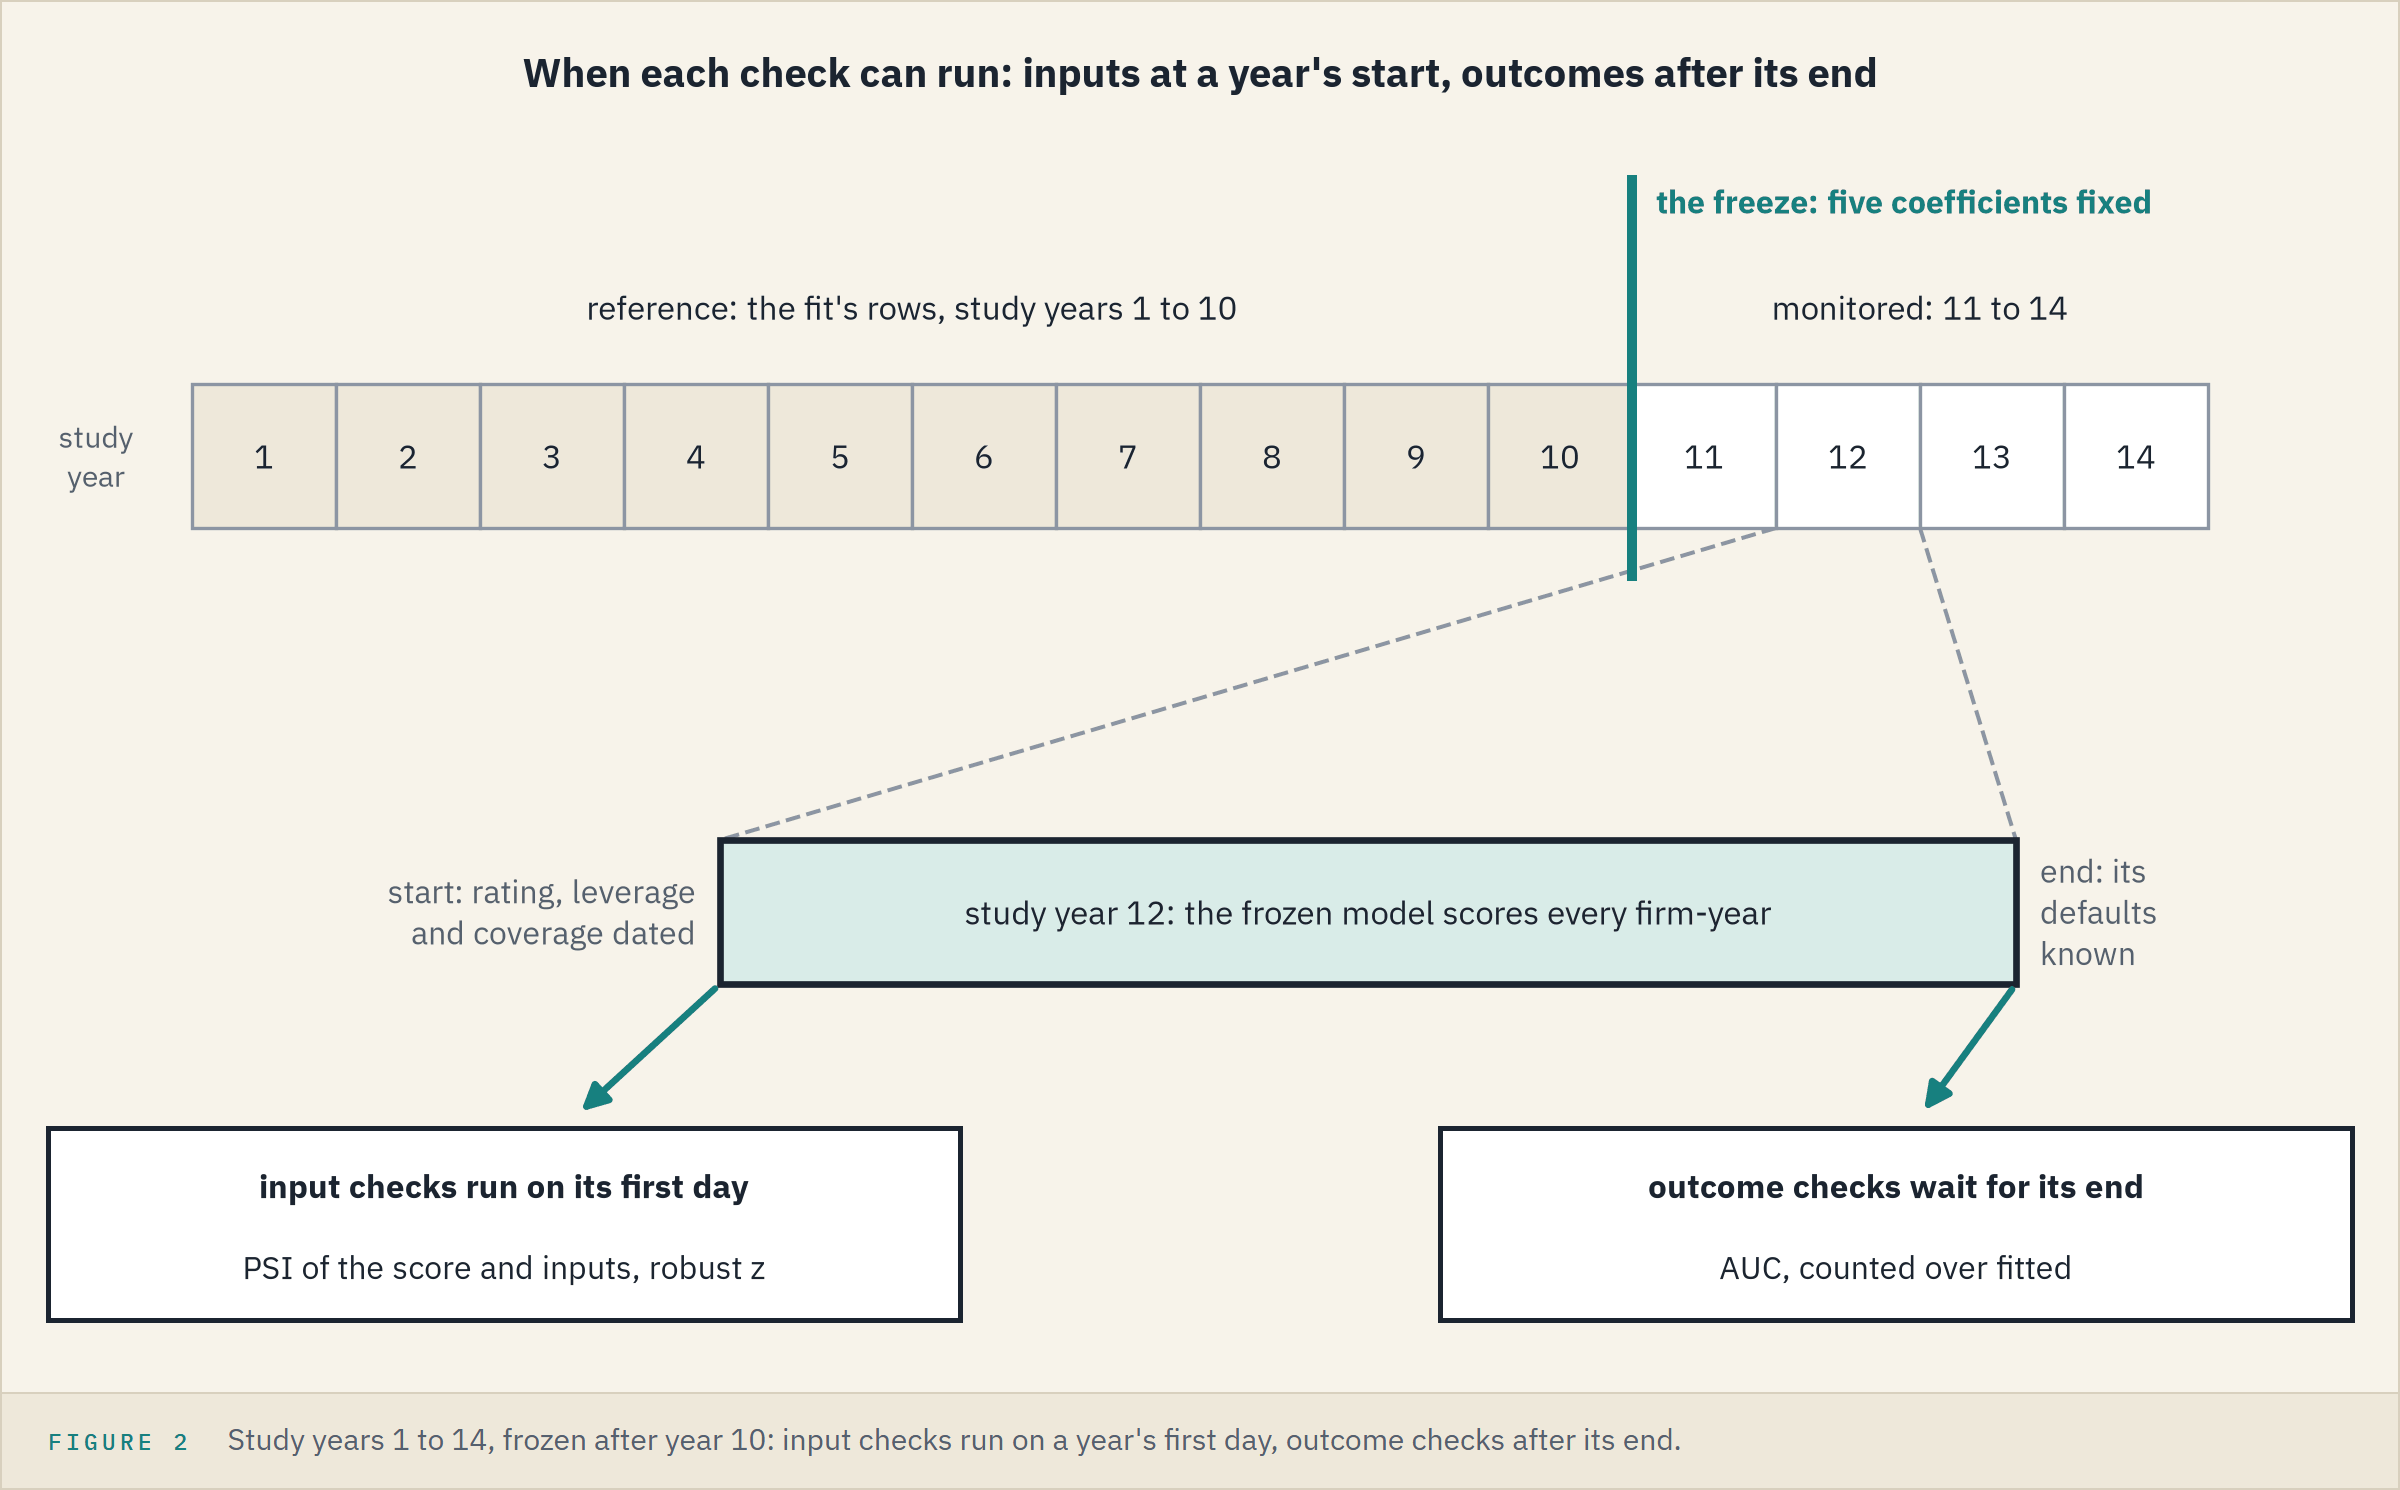

An **input check** reads only what is dated at a year's start, so it can run on the year's first day.

An **outcome check** needs the year's defaults, so it waits for the year to end.

**Every check compares a monitored year with study years 1 to 10, and some checks have to wait for the year to end.**

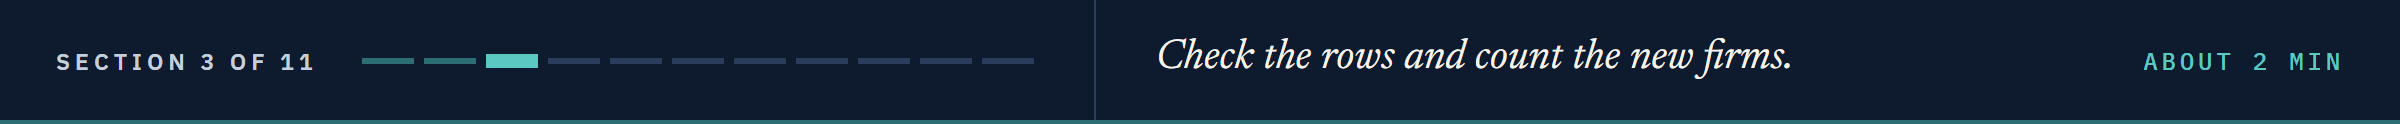

# Data Overview

## Checking for Missing and Duplicate Firm-Years

In [6]:
# blanks in any column, and any firm counted twice in one study year
print("Blanks:", development.isna().sum().sum(), "| duplicated firm-years:", development.duplicated(["firm_id", "study_year"]).sum())

Blanks: 0 | duplicated firm-years: 0


## The Monitored Years at a Glance

A firm's **entry year** is the study year it entered: `study_year - years_since_entry + 1`.

In [7]:
# each firm-year's entry year, and whether the firm entered after the freeze
development["entry_year"] = development["study_year"] - development["years_since_entry"] + 1
development["after_freeze"] = (development["entry_year"] > FIT_END).astype(int)

# each monitored year's firm-years, defaults, and percent entered after year 10
glance = development[~in_reference].groupby("study_year").agg(firm_years=("default", "size"), defaults=("default", "sum"), after_freeze=("after_freeze", "mean"))
glance["after_freeze"] = (100 * glance["after_freeze"]).round(1)
print(f"Counted default rate: {100 * development.loc[in_reference, 'default'].mean():.2f} percent a year in study years 1 to 10 | {100 * development.loc[~in_reference, 'default'].mean():.2f} in 11 to 14")
glance

Counted default rate: 2.03 percent a year in study years 1 to 10 | 1.64 in 11 to 14


,firm_years,defaults,after_freeze
study_year,,,
11,1792,20,13.4
12,1897,23,24.9
13,2008,40,33.9
14,2101,45,41.7


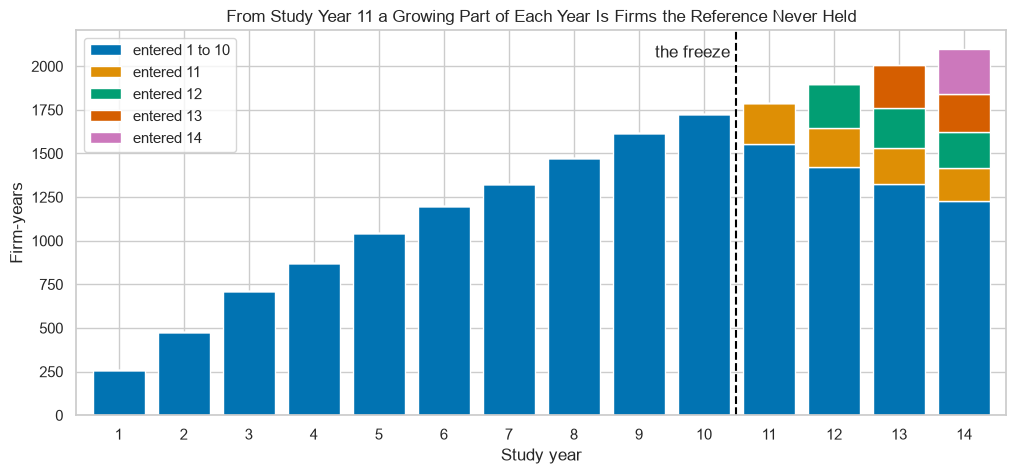

In [8]:
# firm-years by study year, stacked by when each firm entered: study years 1 to 10 as one block, then 11 to 14 each
period = np.where(development["entry_year"] <= FIT_END, "entered 1 to 10", "entered " + development["entry_year"].astype(str))
ax = pd.crosstab(development["study_year"], period).plot.bar(stacked=True, figsize=(12, 5), width=0.8)
ax.axvline(9.5, color="black", linestyle="--")
ax.text(9.4, 2050, "the freeze", ha="right")
ax.set(xlabel="Study year", ylabel="Firm-years", title="From Study Year 11 a Growing Part of Each Year Is Firms the Reference Never Held")
ax.tick_params(axis="x", rotation=0)
ax.legend(title=None, loc="upper left")
plt.show()

The counted default rate of these invented firms was 2.03 percent a year in study years 1 to 10, and 1.64 in 11 to 14.

**Clean rows, and a growing share of each monitored year is firms the reference never held.**

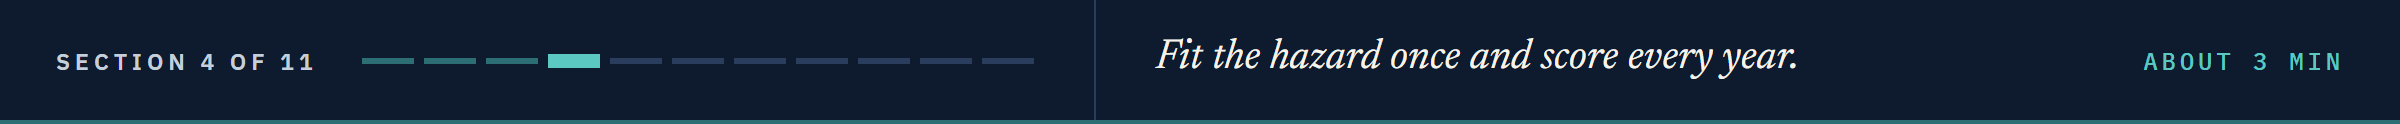

# Model Building: Freezing Day 5's Hazard

## One Fit on Study Years 1 to 10

This is Day 5's fit for test year 11: the same four features, the same rows.

In [9]:
# one fit on the reference rows; these five numbers stay fixed for the rest of the day
model = sm.Logit(development.loc[in_reference, "default"], sm.add_constant(development.loc[in_reference, FEATURES])).fit(disp=0)
pd.DataFrame({"coefficient": model.params, "odds ratio": np.exp(model.params)}).round(4)

,coefficient,odds ratio
const,-8.5415,0.0002
rating_score,0.3629,1.4375
leverage,0.1580,1.1711
log_coverage,-0.6985,0.4973
early_years,0.4047,1.4989


### Interpretation of the Coefficients

One notch toward CCC multiplies the odds of a default in that year by 1.4375, the other inputs held (Day 5's reading).

## Scoring Every Firm-Year

In [10]:
# the frozen model's default probability for every development firm-year
development["fitted"] = model.predict(sm.add_constant(development[FEATURES]))
reference = development[in_reference]
monitored = development[~in_reference]
print(f"Reference firm-years: median {reference['fitted'].median():.4f} | 90th percentile {reference['fitted'].quantile(0.9):.4f}")

Reference firm-years: median 0.0055 | 90th percentile 0.0563


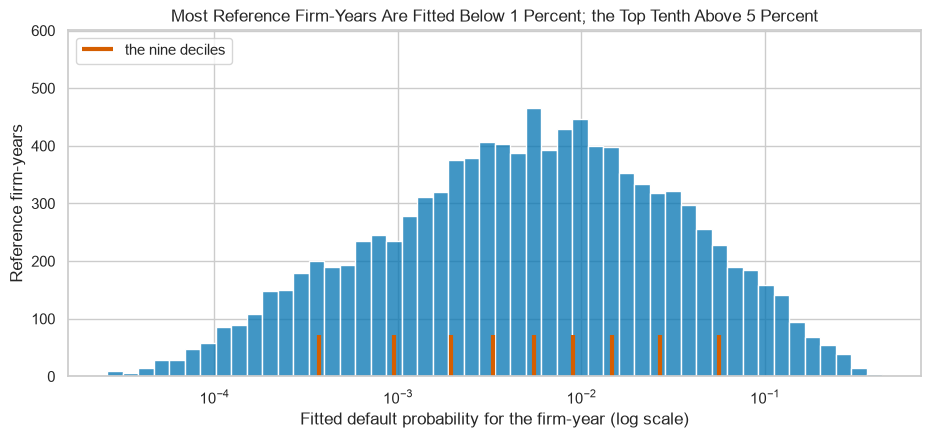

In [11]:
# the reference's fitted chances on a log axis, its nine deciles as a rug: the bins every score PSI will use
score_deciles = np.quantile(reference["fitted"], np.arange(1, 10) / 10)
plt.figure(figsize=(11, 4.5))
sns.histplot(reference["fitted"], log_scale=True, bins=50)
sns.rugplot(x=score_deciles, height=0.12, color="C3", linewidth=3, label="the nine deciles")
plt.xlabel("Fitted default probability for the firm-year (log scale)")
plt.ylabel("Reference firm-years")
plt.title("Most Reference Firm-Years Are Fitted Below 1 Percent; the Top Tenth Above 5 Percent")
plt.legend(loc="upper left")
plt.show()

**Predict 1**

The reference rows hold 217 defaults.

Q. The model's 10,705 fitted default probabilities on those same rows: what do they add up to? Write down a number.

## What the Fitted Chances Add Up To

In [12]:
# the fitted chances summed over the reference rows, beside the defaults counted there
in_sample_auc = roc_auc_score(reference["default"], reference["fitted"])
print(f"Sum of fitted: {reference['fitted'].sum():.10f} | defaults counted: {reference['default'].sum()}")
print(f"In-sample AUC on study years 1 to 10: {in_sample_auc:.4f}")

Sum of fitted: 217.0000000000 | defaults counted: 217
In-sample AUC on study years 1 to 10: 0.8693


A logistic fit with a constant solves one equation for each coefficient, and the constant's equation makes the fitted chances add up to the defaults on the fit's own rows.

Course 5's Day 13 summed fitted chances into an expected count on rows outside its fit; here they are the fit's own rows.

The AUC of 0.8693 is in-sample: the model saw these defaults.

**On the reference years the level matches by construction; only later years can show a gap.**

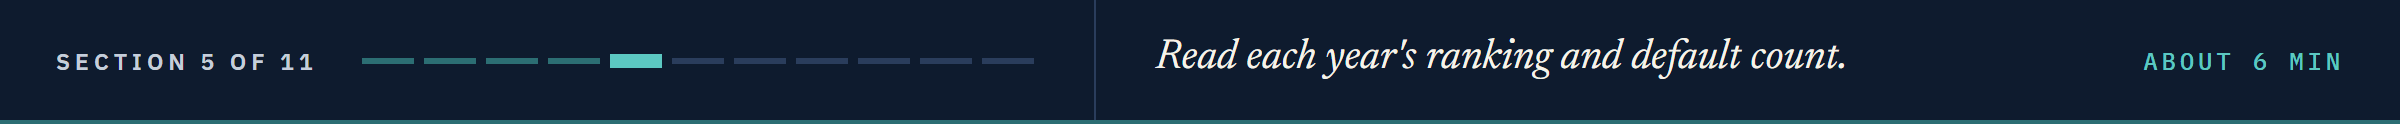

# The Outcome Checks

## Ranking and Level, Year by Year

Day 5's two outcome checks: the AUC for the ranking, and counted over fitted for the level.

In [13]:
# each monitored year: defaults counted, the model's count (the sum of its fitted chances), the AUC and the ratio
outcomes = monitored.groupby("study_year").agg(counted=("default", "sum"), fitted_count=("fitted", "sum"))
outcomes["AUC"] = [roc_auc_score(rows["default"], rows["fitted"]) for _, rows in monitored.groupby("study_year")]
outcomes["counted over fitted"] = outcomes["counted"] / outcomes["fitted_count"]
pooled_auc = roc_auc_score(monitored["default"], monitored["fitted"])
print(f"Pooled 11 to 14: {monitored['default'].sum()} counted against {monitored['fitted'].sum():.2f} fitted | AUC {pooled_auc:.4f}")
outcomes.round(4)

Pooled 11 to 14: 128 counted against 169.16 fitted | AUC 0.8915


,counted,fitted_count,AUC,counted over fitted
study_year,,,,
11,20,33.1171,0.8944,0.6039
12,23,38.8466,0.9170,0.5921
13,40,44.3330,0.8833,0.9023
14,45,52.8681,0.8773,0.8512


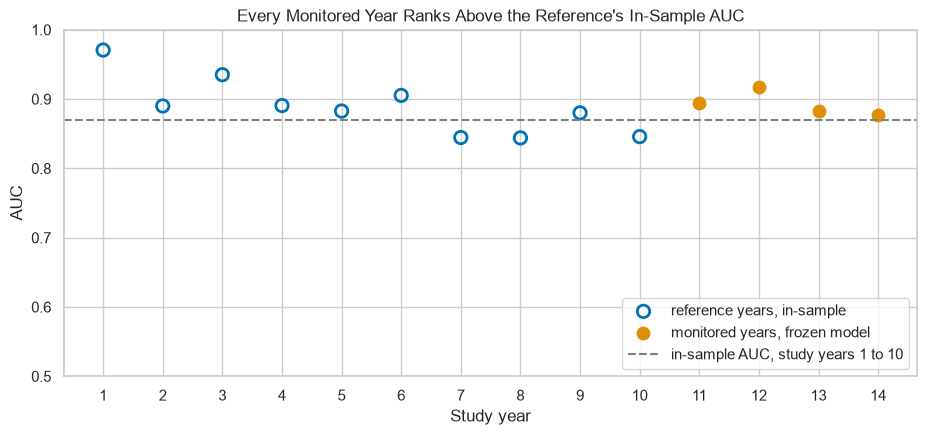

In [14]:
# the AUC in every study year: the reference years in-sample (hollow), the monitored years scored by the frozen model
auc_by_year = pd.Series({year: roc_auc_score(rows["default"], rows["fitted"]) for year, rows in development.groupby("study_year")})
plt.figure(figsize=(11, 4.5))
plt.scatter(auc_by_year.index[:10], auc_by_year.iloc[:10], s=80, facecolors="none", edgecolors="C0", linewidths=2, label="reference years, in-sample")
plt.scatter(auc_by_year.index[10:], auc_by_year.iloc[10:], s=80, color="C1", label="monitored years, frozen model")
plt.axhline(in_sample_auc, color="gray", linestyle="--", label="in-sample AUC, study years 1 to 10")
plt.xticks(auc_by_year.index)
plt.ylim(0.5, 1)
plt.xlabel("Study year")
plt.ylabel("AUC")
plt.title("Every Monitored Year Ranks Above the Reference's In-Sample AUC")
plt.legend(loc="lower right")
plt.show()

Every monitored year's AUC sits above the in-sample 0.8693.

Every monitored year counted fewer defaults than the model's count: 128 against 169.16 pooled.

## How Unlikely Is a Count This Low

The **Poisson distribution** is the count of many rare chances, its mean and its variance both the fitted count (Course 5's Day 13 expected count).
`stats.poisson.cdf(k, mu)` is the chance of k or fewer, and `stats.poisson.interval(0.95, mu)` the whole counts that hold at least the middle 95 percent.

In [15]:
# the chance of the counted defaults or fewer, given each year's fitted count
outcomes["chance this low or lower"] = stats.poisson.cdf(outcomes["counted"], outcomes["fitted_count"])

# year 11's middle 95 percent of counts
low, high = stats.poisson.interval(0.95, outcomes.loc[11, "fitted_count"])
print(f"Year 11: {outcomes.loc[11, 'counted']} counted | 95 percent range {low:.0f} to {high:.0f} on {outcomes.loc[11, 'fitted_count']:.2f} fitted")
outcomes["chance this low or lower"].round(4)

Year 11: 20 counted | 95 percent range 22 to 45 on 33.12 fitted


study_year
11    0.0099
12    0.0043
13    0.2881
14    0.1551
Name: chance this low or lower, dtype: float64

Year 11's 20 defaults sit below its range of 22 to 45; a count that low or lower has a chance of 0.0099.

Day 5 put the same year, scored by the same fit, at -2.38 standard deviations from the model's count.

**Predict 2**

Day 5's walk-forward put study year 10 at 1.54 times its model's count, from a model fitted on study years 1 to 9.
The frozen fit includes year 10's own rows.

Q. What is year 10's counted over fitted under the frozen fit? Write down a number.

## The Reference Years, One at a Time

In [16]:
# every study year: counted, fitted, the ratio of the two, and the whole counts holding the middle 95 and 99 percent
years = development.groupby("study_year").agg(counted=("default", "sum"), fitted=("fitted", "sum"))
years["ratio"] = years["counted"] / years["fitted"]
years["low 95"], years["high 95"] = stats.poisson.interval(0.95, years["fitted"])
years["low 99"], years["high 99"] = stats.poisson.interval(0.99, years["fitted"])
years[["low 95", "high 95", "low 99", "high 99"]] = years[["low 95", "high 95", "low 99", "high 99"]].astype(int)
outside_95 = (years["counted"] < years["low 95"]) | (years["counted"] > years["high 95"])
print("Reference years outside their 95 percent range:", outside_95.loc[:FIT_END].sum(), "of the 10")
years.round(2)

Reference years outside their 95 percent range: 1 of the 10


,counted,fitted,ratio,low 95,high 95,low 99,high 99
study_year,,,,,,,
1,2,4.03,0.50,1,8,0,10
2,9,9.63,0.93,4,16,3,18
3,9,16.23,0.55,9,25,7,27
4,17,21.43,0.79,13,31,11,34
5,25,23.61,1.06,15,34,12,37
6,23,24.46,0.94,15,35,13,38
7,32,26.59,1.20,17,37,14,41
8,23,27.81,0.83,18,39,15,42
9,32,31.58,1.01,21,43,18,47


`stats.poisson.pmf(k, mu)` is the chance of exactly k, as `stats.binom.pmf` was in Course 5's Day 2.
The **count ladder** draws, for each study year, the Poisson chance of every whole count sideways about the year, on one scale for all fourteen.
The 95 percent range is dark, the 99 percent range lighter, and the counted defaults a dot.

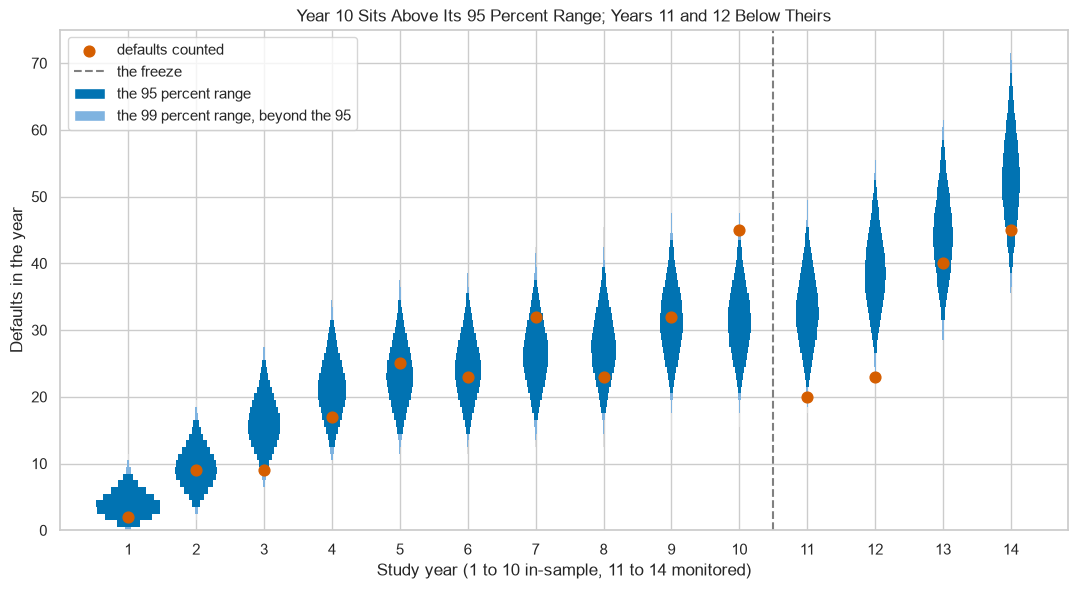

In [17]:
# the count ladder: each year's Poisson chances drawn sideways; the smallest fitted count has the tallest peak, so it sets the scale
counts = np.arange(0, 80)
widest = stats.poisson.pmf(counts, years["fitted"].min()).max()
fig, ax = plt.subplots(figsize=(13, 6.5))
for year, row in years.iterrows():
    half = 0.47 * stats.poisson.pmf(counts, row["fitted"]) / widest
    shade = np.where((counts >= row["low 95"]) & (counts <= row["high 95"]), "C0", np.where((counts >= row["low 99"]) & (counts <= row["high 99"]), "#7fb3e0", "#dddddd"))
    ax.barh(counts, 2 * half, left=year - half, height=1, color=shade, linewidth=0)
for colour, name in [("C0", "the 95 percent range"), ("#7fb3e0", "the 99 percent range, beyond the 95")]:
    ax.barh(-10, 0, color=colour, label=name)
ax.scatter(years.index, years["counted"], color="C3", s=60, zorder=3, label="defaults counted")
ax.axvline(FIT_END + 0.5, color="gray", linestyle="--", label="the freeze")
ax.set(xticks=years.index, ylim=(0, 75), xlabel="Study year (1 to 10 in-sample, 11 to 14 monitored)", ylabel="Defaults in the year", title="Year 10 Sits Above Its 95 Percent Range; Years 11 and 12 Below Theirs")
ax.legend(loc="upper left")
plt.show()

In [18]:
# Day 3's measure: each year's gap in units of its independent sd, squared and averaged
sd = development.groupby("study_year")["fitted"].apply(lambda p: np.sqrt((p * (1 - p)).sum()))
gap = (years["counted"] - years["fitted"]) / sd
print(f"Average squared gap: reference years {(gap.loc[:FIT_END] ** 2).mean():.2f} | monitored years {(gap.loc[FIT_END + 1:] ** 2).mean():.2f}")

Average squared gap: reference years 1.42 | monitored years 3.64


The ten reference years add to 217 against 217, yet one by one they run from 0.50 to 1.42.

Year 10 counted 45 against 31.63, above its 95 percent range of 21 to 43 and inside its 99; Day 3 and Day 5 also found year 10 high.

Years 11 and 12 sit below their 95 percent ranges, and year 12's 23 below its 99 percent range of 24 to 56.

The Poisson range assumes independent defaults and allows for no clustering: Day 3's average squared gap, about 1 under independence, reads 1.42 in the reference years and 3.64 in the monitored.

**The ranking held in every monitored year; the level fell short of the model's count, by more than chance alone in years 11 and 12.**

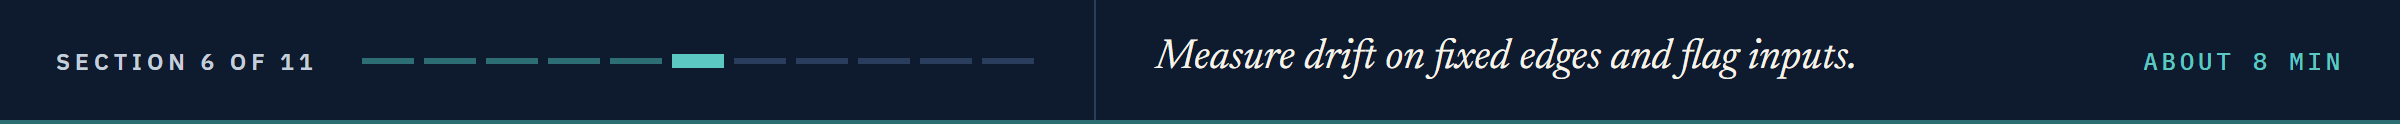

# The Input Checks

## Day 8's Three Functions, Repeated

In [19]:
def quantile_edges(reference, bins=10):
    """The reference's quantile edges for this many bins, equal edges merged."""
    return np.unique(np.quantile(reference, np.arange(1, bins) / bins))

def shares(sample, edges):
    """The sample's share in each bin, in bin order; the end bins are open."""
    return pd.cut(sample, np.concatenate([[-np.inf], edges, [np.inf]])).value_counts(normalize=True, sort=False)

def psi(reference, compared, edges, floor=0.0001):
    """PSI of the compared sample against the reference on fixed edges, each share floored first."""
    reference_share = shares(reference, edges).clip(lower=floor)
    compared_share = shares(compared, edges).clip(lower=floor)
    return ((compared_share - reference_share) * np.log(compared_share / reference_share)).sum()

## Edges Fixed on the Reference

In [20]:
# the score and the three inputs: each one's edges cut on the 10,705 reference rows alone
CHECKS = ["fitted", "rating_score", "leverage", "log_coverage"]
EDGES = {column: quantile_edges(reference[column]) for column in CHECKS}
print("Edges for each check:", {column: len(edges) for column, edges in EDGES.items()})

Edges for each check: {'fitted': 9, 'rating_score': 9, 'leverage': 9, 'log_coverage': 9}


`early_years` is the clock, not a mix, so it is not checked.

**Predict 3**

Day 8 found the leverage of the firms entering in study year 14 at a PSI of 0.856 against the reference years' entrants.
By year 14, 41.7 percent of the firm-years belong to firms that entered after the freeze.

Q. Every firm-year of study year 14 against every reference firm-year, on these edges: what is leverage's PSI? Write down a number.

## Every Firm-Year Against the Reference

In [21]:
# each study year's PSI on the four checks, every firm-year against the 10,705 reference rows
psi_by_year = pd.DataFrame({year: {column: psi(reference[column], rows[column], EDGES[column]) for column in CHECKS} for year, rows in development.groupby("study_year")}).T
print("Pooled 11 to 14:", pd.Series({column: psi(reference[column], monitored[column], EDGES[column]) for column in CHECKS}).round(4).to_dict())
print("Largest reference year against its own reference:", psi_by_year.loc[:FIT_END].max().round(4).to_dict())
psi_by_year.loc[FIT_END + 1:].round(4)

Pooled 11 to 14: {'fitted': 0.0051, 'rating_score': 0.0094, 'leverage': 0.0227, 'log_coverage': 0.0045}
Largest reference year against its own reference: {'fitted': 0.0613, 'rating_score': 0.0179, 'leverage': 0.0411, 'log_coverage': 0.0225}


,fitted,rating_score,leverage,log_coverage
11,0.0047,0.0057,0.0064,0.0087
12,0.0034,0.0082,0.0136,0.0015
13,0.0097,0.0136,0.0307,0.0078
14,0.0240,0.0253,0.0651,0.0183


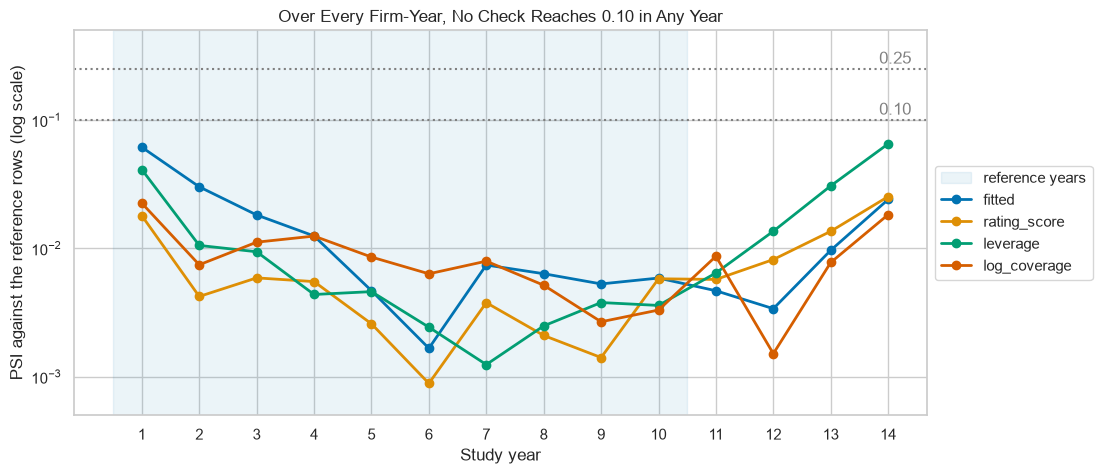

In [22]:
# PSI by study year on a log axis, the reference years shaded, Yurdakul's two ends dotted
plt.figure(figsize=(11, 5))
plt.axvspan(0.5, FIT_END + 0.5, color="C0", alpha=0.08, label="reference years")
for column in CHECKS:
    plt.plot(psi_by_year.index, psi_by_year[column], marker="o", linewidth=2, label=column)
for level in [0.10, 0.25]:
    plt.axhline(level, color="gray", linestyle=":")
    plt.text(14.4, level * 1.1, f"{level:.2f}", ha="right", color="gray")
plt.yscale("log")
plt.ylim(0.0005, 0.5)
plt.xticks(psi_by_year.index)
plt.xlabel("Study year")
plt.ylabel("PSI against the reference rows (log scale)")
plt.title("Over Every Firm-Year, No Check Reaches 0.10 in Any Year")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

Each reference year against the whole reference shows the noise of one year's rows: up to 0.0613, on the score in study year 1, the year with the fewest rows.

Year 14's leverage sits above every reference year's own and far below 0.10.

The dotted lines are the two ends Day 8's story quoted from Yurdakul's abstract (https://scholarworks.wmich.edu/dissertations/3208/): below 0.10 "little shift", 0.25 "significant shift, action required".

## The Stock and the Flow

The **stock** is every firm-year held in a study year; the **flow** is that year's entrants.
Day 8 read the flow, against the reference years' 2,508 entrants on their own edges.

In [23]:
# leverage by monitored year: the stock against the 10,705 reference rows, the flow against the 2,508 reference entrants
reference_entrants = reference[reference["years_since_entry"] == 1]
entrant_edges = quantile_edges(reference_entrants["leverage"])
stock_flow = pd.DataFrame({year: {"stock": psi(reference["leverage"], rows["leverage"], EDGES["leverage"]),
                                  "flow": psi(reference_entrants["leverage"], rows.loc[rows["years_since_entry"] == 1, "leverage"], entrant_edges)}
                           for year, rows in monitored.groupby("study_year")}).T
stock_flow.round(4)

,stock,flow
11,0.0064,0.1099
12,0.0136,0.2680
13,0.0307,0.4342
14,0.0651,0.8560


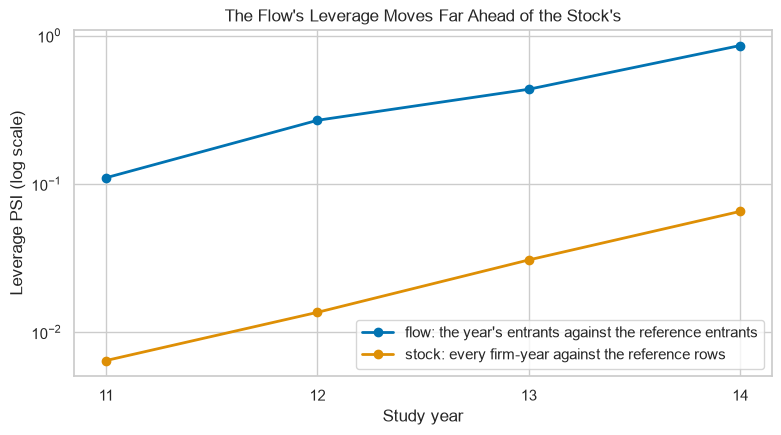

In [24]:
# the two lines on a log axis
plt.figure(figsize=(9, 4.5))
plt.plot(stock_flow.index, stock_flow["flow"], marker="o", linewidth=2, label="flow: the year's entrants against the reference entrants")
plt.plot(stock_flow.index, stock_flow["stock"], marker="o", linewidth=2, label="stock: every firm-year against the reference rows")
plt.yscale("log")
plt.xticks(stock_flow.index)
plt.xlabel("Study year")
plt.ylabel("Leverage PSI (log scale)")
plt.title("The Flow's Leverage Moves Far Ahead of the Stock's")
plt.legend(loc="lower right")
plt.show()

## Where the Mix Moved

**Diverging stacked bars** give one row to a sample: each leverage bin's share less its reference's share, gains stacked right of zero and losses left.
Each bin keeps one colour in every row, from low leverage to high.

In [25]:
# each row's ten bin gaps: the sample's share less its reference's share
gaps = {}
for year, rows in monitored.groupby("study_year"):
    gaps[f"year {year}, stock"] = shares(rows["leverage"], EDGES["leverage"]).to_numpy() - shares(reference["leverage"], EDGES["leverage"]).to_numpy()
    gaps[f"year {year}, flow"] = shares(rows.loc[rows["years_since_entry"] == 1, "leverage"], entrant_edges).to_numpy() - shares(reference_entrants["leverage"], entrant_edges).to_numpy()
gaps = pd.DataFrame(gaps, index=[f"bin {b}" for b in range(1, 11)]).T
print("Share sitting in other bins than the reference would put it:", gaps.clip(lower=0).sum(axis=1).round(2).to_dict())
print("Year 14, top bin: stock", round(gaps.loc["year 14, stock", "bin 10"], 3), "| flow", round(gaps.loc["year 14, flow", "bin 10"], 3))

Share sitting in other bins than the reference would put it: {'year 11, stock': 0.03, 'year 11, flow': 0.14, 'year 12, stock': 0.04, 'year 12, flow': 0.19, 'year 13, stock': 0.07, 'year 13, flow': 0.27, 'year 14, stock': 0.11, 'year 14, flow': 0.34}
Year 14, top bin: stock 0.067 | flow 0.269


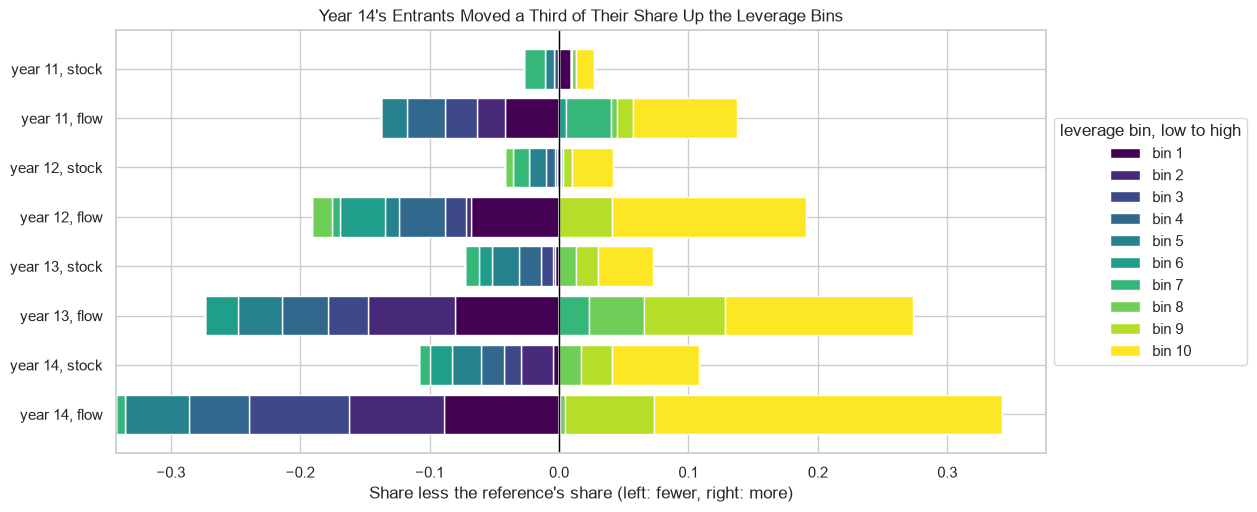

In [26]:
# diverging stacked bars: each bin's gain stacked right of zero and its loss left, one colour a bin
colours = plt.cm.viridis(np.linspace(0, 1, 10))
gains, losses = gaps.clip(lower=0), gaps.clip(upper=0)
fig, ax = plt.subplots(figsize=(12, 5.5))
for b in range(10):
    ax.barh(gaps.index, gains.iloc[:, b], left=gains.iloc[:, :b].sum(axis=1), color=colours[b], label=f"bin {b + 1}")
    ax.barh(gaps.index, losses.iloc[:, b], left=losses.iloc[:, :b].sum(axis=1), color=colours[b])
ax.axvline(0, color="black", linewidth=1)
ax.invert_yaxis()
ax.set(xlabel="Share less the reference's share (left: fewer, right: more)", title="Year 14's Entrants Moved a Third of Their Share Up the Leverage Bins")
ax.legend(title="leverage bin, low to high", loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

A row's gaps sum to zero, so its two sides are equally long: that length is the share sitting in other bins than its reference would put it.

Year 14's entrants hold 0.269 more of their share in the top leverage bin; the stock holds 0.067 more.

**A shift in the new firms reaches the whole book slowly, so a check on every firm-year sees it years late.**

## Unusual Inputs

Day 6's rule, unchanged: a |robust z| above 3.5, the median and MAD taken from the reference rows and held fixed for the monitored years.

In [27]:
# Day 6's robust z on the three inputs: the centre and the scale come from the reference rows only
INPUTS = ["rating_score", "leverage", "log_coverage"]
centre = reference[INPUTS].median()
mad = (reference[INPUTS] - centre).abs().median()
robust_z = (monitored[INPUTS] - centre) / (1.4826 * mad)
flags = (robust_z.abs() > 3.5).any(axis=1)
print("Centre:", centre.round(4).to_dict(), "| MAD:", mad.round(4).to_dict())
print("Monitored firm-years flagged:", flags.sum(), "| by input:", (robust_z.abs() > 3.5).sum().to_dict())
print("Reference firm-years flagged:", (((reference[INPUTS] - centre) / (1.4826 * mad)).abs() > 3.5).any(axis=1).sum())

Centre: {'rating_score': 10.0, 'leverage': 4.05, 'log_coverage': 1.7834} | MAD: {'rating_score': 3.0, 'leverage': 0.99, 'log_coverage': 0.451}
Monitored firm-years flagged: 2 | by input: {'rating_score': 0, 'leverage': 1, 'log_coverage': 1}
Reference firm-years flagged: 7


In [28]:
# the furthest a rating can reach: AAA (1) and CCC (18) in robust units
rating_reach = (np.array([1, 18]) - centre["rating_score"]) / (1.4826 * mad["rating_score"])
print(f"Rating's robust z runs from {rating_reach[0]:.2f} to {rating_reach[1]:.2f}")

Rating's robust z runs from -2.02 to 1.80


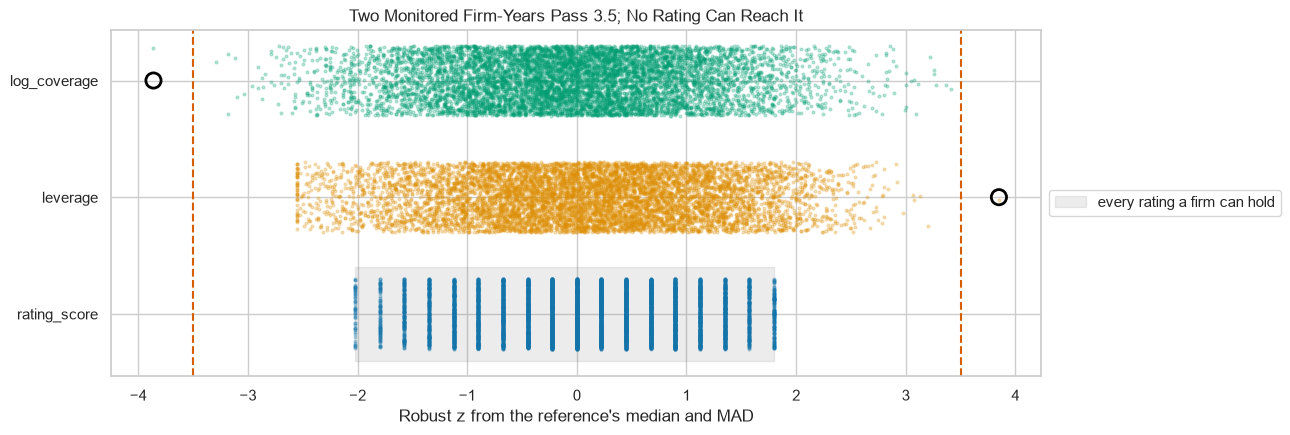

In [29]:
# each monitored firm-year's robust z by input, with jitter from the seeded generator; the 3.5 lines and rating's reach
# (fill_betweenx is fill_between turned on its side: it shades between two x values over a span of y)
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(12, 4.5))
for i, column in enumerate(INPUTS):
    ax.scatter(robust_z[column], i + rng.uniform(-0.3, 0.3, len(robust_z)), s=4, alpha=0.25, color=f"C{i}")
    ax.scatter(robust_z.loc[robust_z[column].abs() > 3.5, column], [i] * (robust_z[column].abs() > 3.5).sum(), s=120, facecolors="none", edgecolors="black", linewidths=2)
ax.fill_betweenx([-0.4, 0.4], rating_reach[0], rating_reach[1], color="gray", alpha=0.15, label="every rating a firm can hold")
for line in [-3.5, 3.5]:
    ax.axvline(line, color="C3", linestyle="--")
ax.set(yticks=range(3), yticklabels=INPUTS, xlabel="Robust z from the reference's median and MAD", title="Two Monitored Firm-Years Pass 3.5; No Rating Can Reach It")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

Two of 7,798 monitored firm-years are flagged, one by leverage and one by log coverage, against 7 of 10,705 in the reference.

**Over the whole book the inputs barely moved, and no row looks broken.**

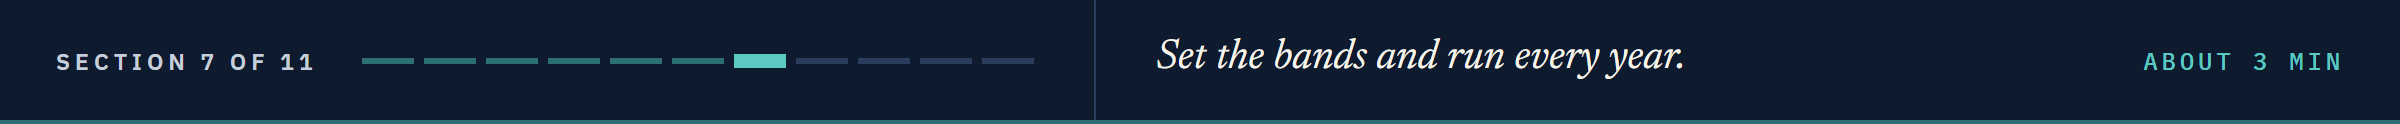

# One Report per Year

## The Bands and the Report

A **status** reads each check against a band: green, amber or red.
PSI's band takes Yurdakul's two ends: green below 0.10, amber below 0.25, red from 0.25.
The other two bands are the course's choice for this exercise.
The AUC is green at or above the in-sample 0.8693 less 0.03 and amber at or above it less 0.07, so a rise is green.
The count is green inside its 95 percent Poisson range and amber inside its 99 percent range, both ends counted inside.

`a if test else b if test2 else c` picks the first word whose test holds, read left to right.

In [30]:
def monitoring_report(reference, current, edges):
    """Four PSIs, the AUC and counted over fitted of current against reference, each with its status."""
    values = {f"PSI {column}": psi(reference[column], current[column], edges[column]) for column in CHECKS}
    status = {name: "green" if value < 0.10 else "amber" if value < 0.25 else "red" for name, value in values.items()}
    in_sample = roc_auc_score(reference["default"], reference["fitted"])
    values["AUC"] = roc_auc_score(current["default"], current["fitted"])
    status["AUC"] = "green" if values["AUC"] >= in_sample - 0.03 else "amber" if values["AUC"] >= in_sample - 0.07 else "red"
    counted, fitted_count = current["default"].sum(), current["fitted"].sum()
    low_95, high_95 = stats.poisson.interval(0.95, fitted_count)
    low_99, high_99 = stats.poisson.interval(0.99, fitted_count)
    values["Counted over fitted"] = counted / fitted_count
    status["Counted over fitted"] = "green" if low_95 <= counted <= high_95 else "amber" if low_99 <= counted <= high_99 else "red"
    return pd.DataFrame({"Value": values, "Status": status})

# the three status colours, from the course palette
STATUS_COLOURS = {"green": "#029E73", "amber": "#ECE133", "red": "#D55E00"}

In [31]:
# the pooled monitored years, 11 to 14, against the reference
pooled_report = monitoring_report(reference, monitored, EDGES)
low, high = stats.poisson.interval(0.99, monitored["fitted"].sum())
print(f"Checks not green: {(pooled_report['Status'] != 'green').sum()} | the count's 99 percent range: {low:.0f} to {high:.0f}")
pooled_report.round(4)

Checks not green: 1 | the count's 99 percent range: 137 to 204


,Value,Status
PSI fitted,0.0051,green
PSI rating_score,0.0094,green
PSI leverage,0.0227,green
PSI log_coverage,0.0045,green
AUC,0.8915,green
Counted over fitted,0.7567,red


The count, 128 against a 99 percent range of 137 to 204, is the one check not green.

## Fourteen Reports

In [32]:
# every study year through the same function: one column of values and one of statuses a year
reports = {year: monitoring_report(reference, rows, EDGES) for year, rows in development.groupby("study_year")}
values = pd.DataFrame({year: report["Value"] for year, report in reports.items()})
statuses = pd.DataFrame({year: report["Status"] for year, report in reports.items()})
print("Checks not green, by year:", (statuses != "green").sum().to_dict())

Checks not green, by year: {1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10: 1, 11: 1, 12: 1, 13: 0, 14: 0}


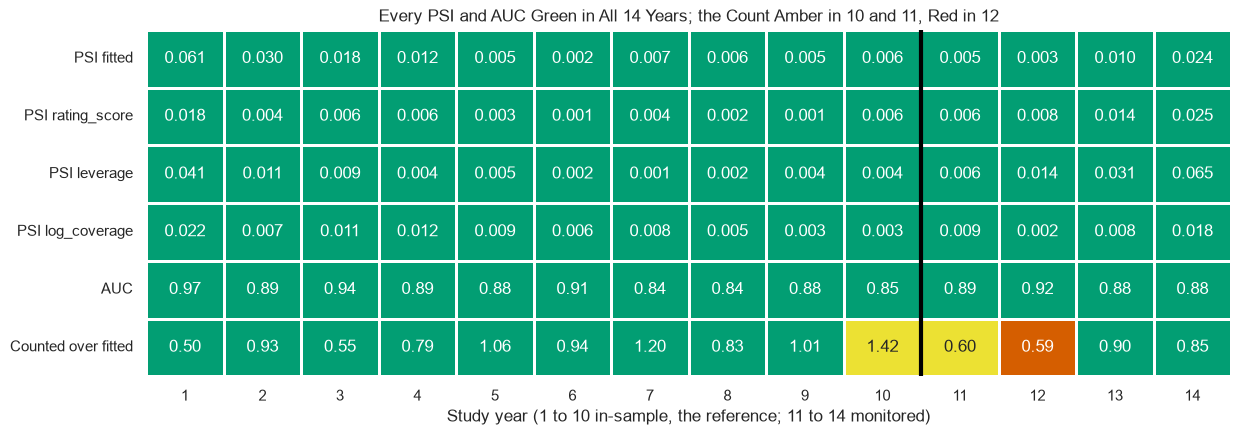

In [33]:
# the status grid: colour by status, value written in (AUC and the count to two places)
codes = (statuses == "amber") * 1 + (statuses == "red") * 2
labels = [[f"{v:.2f}" if name in ["AUC", "Counted over fitted"] else f"{v:.3f}" for v in values.loc[name]] for name in values.index]
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(codes, cmap=list(STATUS_COLOURS.values()), vmin=0, vmax=2, annot=labels, fmt="", cbar=False, linewidths=1, linecolor="white", ax=ax)
ax.axvline(FIT_END, color="black", linewidth=3)
ax.set(xlabel="Study year (1 to 10 in-sample, the reference; 11 to 14 monitored)", ylabel="", title="Every PSI and AUC Green in All 14 Years; the Count Amber in 10 and 11, Red in 12")
plt.show()

The count reads amber in years 10 and 11 and red in 12; year 10 is a reference year, read in-sample.

**One report a year flags the level in years 11 and 12, and has no column that says why.**

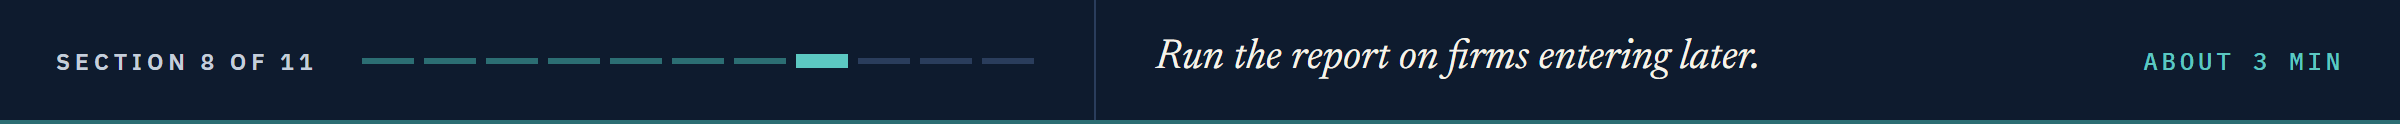

# Case Study: The New Firms Alone

A colleague asks two questions.
What does the report say on the firms that entered after the freeze?
And on a copy where each year's ratings are shuffled among its firm-years?

## Firms Entering in Study Years 11 to 14

In [34]:
# the monitored firm-years of firms that entered after the freeze, and their four PSIs against the reference
new_firms = monitored[monitored["after_freeze"] == 1]
print("Firm-years:", len(new_firms), "| firms:", new_firms["firm_id"].nunique(), "| defaults:", new_firms["default"].sum())
pd.Series({column: psi(reference[column], new_firms[column], EDGES[column]) for column in CHECKS}).round(4)

Firm-years: 2269 | firms: 996 | defaults: 65


fitted          0.2450
rating_score    0.2104
leverage        0.2595
log_coverage    0.0865
dtype: float64

These 996 firms are Day 8's entrants of study years 11 to 14.

**Predict 4**

The new firms' PSIs run up to 0.26.

Q. What is their AUC under the frozen model? Write down a number.

## Their Ranking and Level

In [35]:
# the report on the new firms, beside the older firms of the same years
older_firms = monitored[monitored["after_freeze"] == 0]
new_report = monitoring_report(reference, new_firms, EDGES)
print("Older firms:", len(older_firms), "firm-years,", older_firms["default"].sum(), "defaults")
pd.concat({"new firms": new_report, "older firms": monitoring_report(reference, older_firms, EDGES)}, axis=1).round(4)

Older firms: 5529 firm-years, 63 defaults


new firms        older firms       
                        Value Status       Value Status
PSI fitted             0.2450  amber      0.0223  green
PSI rating_score       0.2104  amber      0.0122  green
PSI leverage           0.2595    red      0.0133  green
PSI log_coverage       0.0865  green      0.0068  green
AUC                    0.8801  green      0.8889  green
Counted over fitted    0.7720  amber      0.7415  amber

In [36]:
# the AUC by year for the whole book, the new firms and the older firms, with the new firms' defaults a year
by_group = pd.DataFrame({name: [roc_auc_score(year["default"], year["fitted"]) for _, year in rows.groupby("study_year")]
                         for name, rows in [("whole book", monitored), ("new firms", new_firms), ("older firms", older_firms)]}, index=range(11, 15))
by_group["new firms' defaults"] = new_firms.groupby("study_year")["default"].sum()
by_group.round(4)

,whole book,new firms,older firms,new firms' defaults
11,0.8944,0.8917,0.8870,6
12,0.9170,0.9624,0.9015,8
13,0.8833,0.8722,0.9037,18
14,0.8773,0.8570,0.8621,33


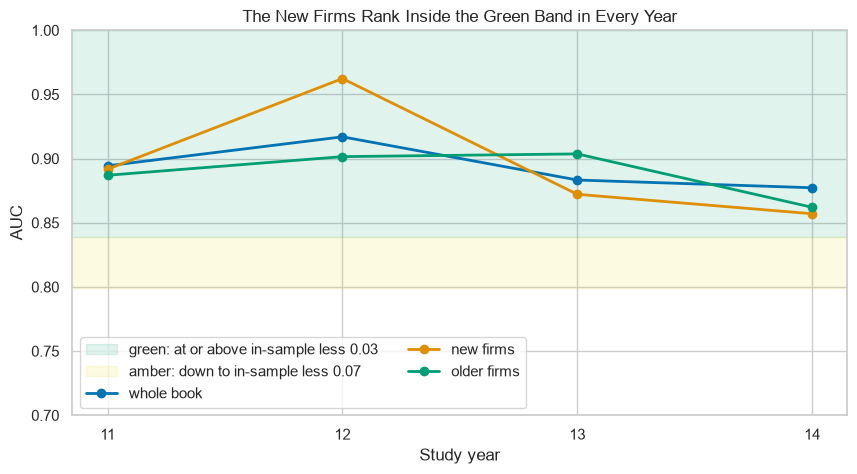

In [37]:
# the three lines over the AUC band
plt.figure(figsize=(10, 5))
plt.axhspan(in_sample_auc - 0.03, 1, color=STATUS_COLOURS["green"], alpha=0.12, label="green: at or above in-sample less 0.03")
plt.axhspan(in_sample_auc - 0.07, in_sample_auc - 0.03, color=STATUS_COLOURS["amber"], alpha=0.15, label="amber: down to in-sample less 0.07")
for name in ["whole book", "new firms", "older firms"]:
    plt.plot(by_group.index, by_group[name], marker="o", linewidth=2, label=name)
plt.xticks(by_group.index)
plt.ylim(0.7, 1)
plt.xlabel("Study year")
plt.ylabel("AUC")
plt.title("The New Firms Rank Inside the Green Band in Every Year")
plt.legend(loc="lower left", ncols=2)
plt.show()

The new firms rank at 0.8801 pooled, green, while their leverage PSI reads red on Yurdakul's 0.25 end.

Their count sits at 0.7720 of the model's, amber, and the older firms' at 0.7415, also amber.

Year 12's 0.9624 rests on 8 defaults.

**The new firms' inputs moved and the model still sorted them; the level fell short for new and older firms alike.**

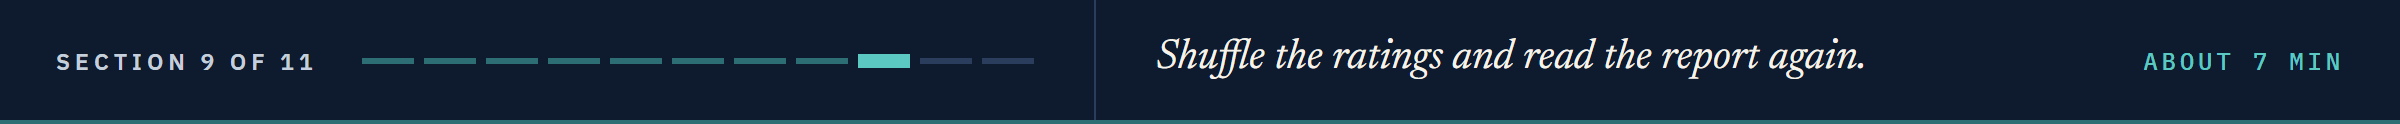

# Case Study: Ratings Shuffled in a Copy

## Planting the Shuffle

`rng.permutation` (Course 4's Day 3) reorders each monitored year's ratings among its firm-years.
Each year keeps the same ratings, and each firm takes another firm's.
The copy is labelled planted, scored by the frozen model, and never written to disk.

In [38]:
# a copy of the monitored years with each year's ratings shuffled among its firm-years, then rescored
rng = np.random.default_rng(SEED)
shuffled = monitored.copy()
for year in range(FIT_END + 1, DEVELOPMENT_END + 1):
    in_year = shuffled["study_year"] == year
    shuffled.loc[in_year, "rating_score"] = rng.permutation(shuffled.loc[in_year, "rating_score"].to_numpy())
shuffled["fitted"] = model.predict(sm.add_constant(shuffled[FEATURES]))

In [39]:
# the planted rows, each year's ratings sorted against the real ones, and rating's correlation with leverage
planted = shuffled["rating_score"] != monitored["rating_score"]
same = (shuffled.sort_values(["study_year", "rating_score"])["rating_score"].to_numpy() == monitored.sort_values(["study_year", "rating_score"])["rating_score"].to_numpy()).all()
print("Planted firm-years:", planted.sum(), "of", len(planted), "| each year's ratings, sorted, the same:", same)
print(f"Rating with leverage: real {monitored['rating_score'].corr(monitored['leverage']):.3f} | shuffled {shuffled['rating_score'].corr(shuffled['leverage']):.3f}")

Planted firm-years: 7165 of 7798 | each year's ratings, sorted, the same: True
Rating with leverage: real 0.698 | shuffled 0.013


**Predict 5**

A shuffle inside a sample leaves its mix where it was (Day 8), so the copy's input PSIs are the real book's: 0.0094, 0.0227 and 0.0045.

Q. Sketch the copy's other three statuses: the score's PSI, the AUC, and counted over fitted.

## The Report on the Copy

In [40]:
# the copy's report beside the real monitored years', and the copy's AUC by year
shuffled_report = monitoring_report(reference, shuffled, EDGES)
print("Shuffled AUC by year:", {year: round(roc_auc_score(rows["default"], rows["fitted"]), 4) for year, rows in shuffled.groupby("study_year")})
pd.concat({"real": pooled_report, "shuffled copy": shuffled_report}, axis=1).round(4)

Shuffled AUC by year: {11: 0.6795, 12: 0.7048, 13: 0.6938, 14: 0.6525}


real        shuffled copy       
                      Value Status         Value Status
PSI fitted           0.0051  green        0.0730  green
PSI rating_score     0.0094  green        0.0094  green
PSI leverage         0.0227  green        0.0227  green
PSI log_coverage     0.0045  green        0.0045  green
AUC                  0.8915  green        0.6838    red
Counted over fitted  0.7567    red        1.0654  green

In [41]:
# Day 6's rule on the copy, with the reference's centre and scale
copy_flags = (((shuffled[INPUTS] - centre) / (1.4826 * mad)).abs() > 3.5).any(axis=1)
print("Flags on the copy:", copy_flags.sum(), "| among the planted rows:", (copy_flags & planted).sum(), "| the same rows as on the real book:", copy_flags.equals(flags))

Flags on the copy: 2 | among the planted rows: 2 | the same rows as on the real book: True


The AUC fell to 0.6838, red, while the score's PSI stayed green and the count turned green at 1.0654.

The robust rule flags the same two rows as before, both among the planted: a shuffled rating stays inside the reference's range.

A frozen model is watched on two kinds of evidence: its inputs, known at a year's start, and its outcomes, known at its end.
The inputs can drift while the ranking holds, and the ranking can fail with every input check green, so a report needs both.

## Where the Defaults Went

An **alluvial diagram** stacks the deciles as blocks on two axes, each sized by count, and joins them with ribbons as wide as the count that moves.

In [42]:
# each of the 128 defaulted firm-years' score decile on the reference's edges, before and after the shuffle
# (labels=False gives each row its bin's number, counted from 0, in place of the interval)
defaulted = monitored["default"] == 1
outer = np.concatenate([[-np.inf], EDGES["fitted"], [np.inf]])
pairs = pd.DataFrame({"before": pd.cut(monitored.loc[defaulted, "fitted"], outer, labels=False) + 1,
                      "after": pd.cut(shuffled.loc[defaulted, "fitted"], outer, labels=False) + 1})
print("Top decile:", (pairs["before"] == 10).sum(), "before,", (pairs["after"] == 10).sum(), "after | stayed in their decile:", (pairs["before"] == pairs["after"]).sum())

Top decile: 83 before, 25 after | stayed in their decile: 27


In [43]:
# one ribbon for each move: stacked by decile before on the left, by decile after on the right, a gap of 3 between deciles
ribbons = pairs.groupby(["before", "after"]).size().rename("width").reset_index()
ribbons["left"] = ribbons["width"].cumsum() - ribbons["width"] + 3 * (ribbons["before"] - 1)
ribbons = ribbons.sort_values(["after", "before"])
ribbons["right"] = ribbons["width"].cumsum() - ribbons["width"] + 3 * (ribbons["after"] - 1)

# every monitored firm-year's share in each decile, real and shuffled, scaled to the 128 defaulted firm-years
behind = pd.DataFrame({"real": shares(monitored["fitted"], EDGES["fitted"]).to_numpy(), "shuffled": shares(shuffled["fitted"], EDGES["fitted"]).to_numpy()}, index=range(1, 11)) * len(pairs)

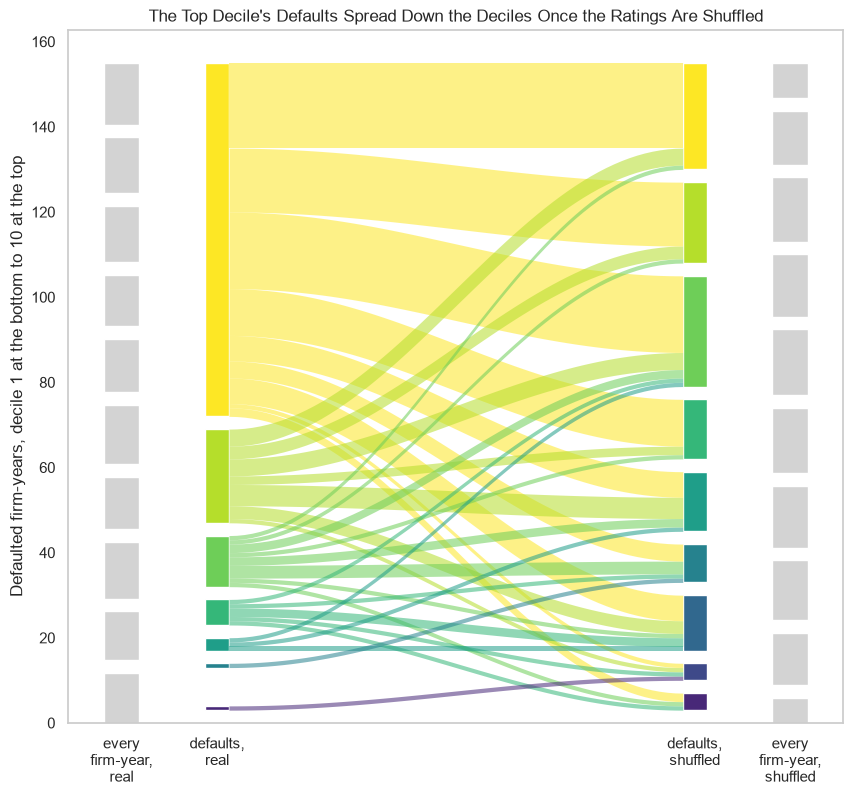

In [44]:
# the alluvial: pale columns for every firm-year, blocks for the defaulted ones, S-shaped ribbons between
path = (1 - np.cos(np.linspace(0, np.pi, 60))) / 2
x = np.linspace(0.12, 0.88, 60)
colours = plt.cm.viridis(np.linspace(0, 1, 10))
fig, ax = plt.subplots(figsize=(10, 9))
for side, pale_x, block_x, decile, edge in [("real", -0.06, 0.1, "before", "left"), ("shuffled", 1.06, 0.9, "after", "right")]:
    ax.bar(pale_x, behind[side], bottom=behind[side].cumsum() - behind[side] + 3 * np.arange(10), width=0.06, color="lightgray")
    blocks = ribbons.groupby(decile).agg(bottom=(edge, "min"), height=("width", "sum"))
    ax.bar(block_x, blocks["height"], bottom=blocks["bottom"], width=0.04, color=colours[blocks.index - 1])
for _, ribbon in ribbons.iterrows():
    bottom = ribbon["left"] + (ribbon["right"] - ribbon["left"]) * path
    ax.fill_between(x, bottom, bottom + ribbon["width"], color=colours[int(ribbon["before"]) - 1], alpha=0.55, linewidth=0)
ax.grid(False)
ax.set(xticks=[-0.06, 0.1, 0.9, 1.06], xticklabels=["every\nfirm-year,\nreal", "defaults,\nreal", "defaults,\nshuffled", "every\nfirm-year,\nshuffled"], ylabel="Defaulted firm-years, decile 1 at the bottom to 10 at the top", title="The Top Decile's Defaults Spread Down the Deciles Once the Ratings Are Shuffled")
plt.show()

The pale columns, every firm-year's decile shares, barely change: PSI reads those heights.

The ribbons cross: 83 defaulted firm-years sat in the top decile before the shuffle, 25 after, and 27 of 128 stayed in their decile.

## Your Turn: How Much Shuffling

The slider takes a share of the monitored firm-years and gives each the copy's rating; every position is a fresh draw from `SEED`.

In [45]:
# the report on the real book with a share of its firm-years given the copy's rating
def draw_share(share=0.5):
    take = np.random.default_rng(SEED).random(len(monitored)) < share
    blend = monitored.copy()
    blend["rating_score"] = np.where(take, shuffled["rating_score"], monitored["rating_score"])
    blend["fitted"] = model.predict(sm.add_constant(blend[FEATURES]))
    report = monitoring_report(reference, blend, EDGES)
    plt.figure(figsize=(11, 4.5))
    plt.barh(report.index, report["Value"], color=[STATUS_COLOURS[s] for s in report["Status"]])
    for y, (value, status) in enumerate(zip(report["Value"], report["Status"])):
        plt.text(value * 1.1, y, f"{value:.4f}, {status}", va="center")
    plt.xscale("log")
    plt.xlim(0.001, 5)
    plt.gca().invert_yaxis()
    plt.xlabel("Value (log scale)")
    plt.title(f"{100 * share:.0f} Percent of Firm-Years Given a Shuffled Rating")
    plt.show()

In [46]:
# your turn: move the share shuffled
interact(draw_share, share=(0.0, 1.0, 0.05));

interactive(children=(FloatSlider(value=0.5, description='share', max=1.0, step=0.05), Output()), _dom_classes…

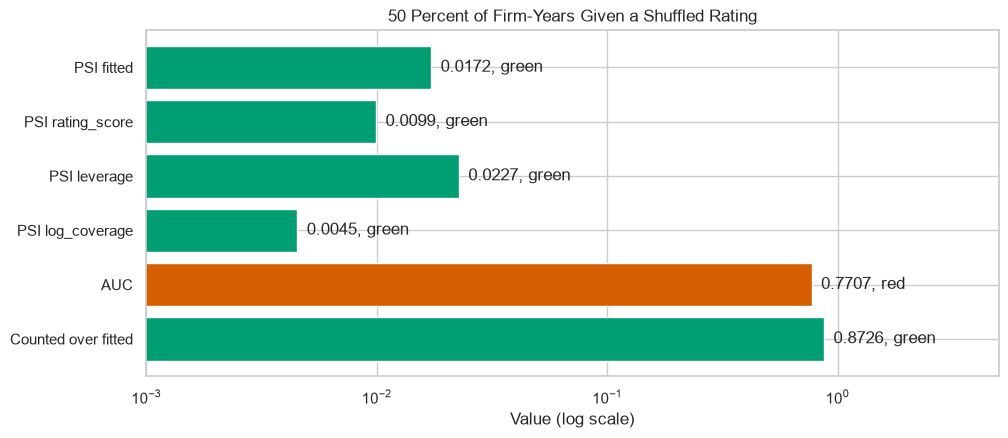

In [47]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_share(share=0.5)

With half the firm-years shuffled, the AUC is already red while rating's PSI barely moves.

**A check on inputs cannot see a link between an input and default; only outcomes can, and they arrive after the year.**

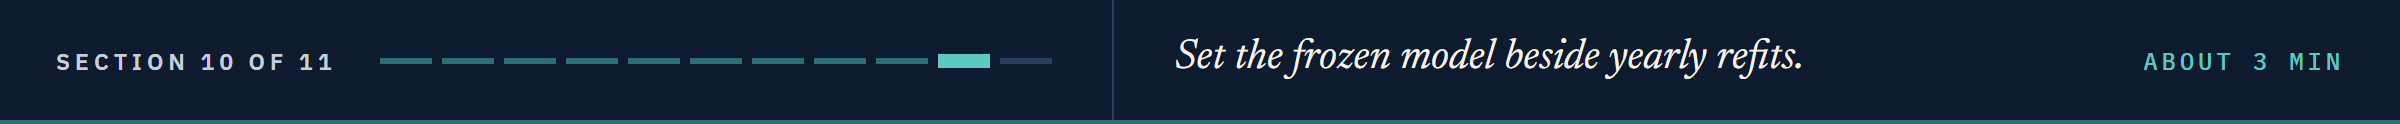

# Model Performance Comparison

## Frozen Against Refitted Each Year

Day 5's walk-forward, repeated as one cell over test years 11 to 14: each year refitted on every earlier study year.

In [48]:
# each test year refitted on every earlier study year, beside the frozen model's numbers
refit = {}
for test_year in range(FIT_END + 1, DEVELOPMENT_END + 1):
    train = development[development["study_year"] < test_year]
    test = development[development["study_year"] == test_year]
    fit = sm.Logit(train["default"], sm.add_constant(train[FEATURES])).fit(disp=0)
    chances = fit.predict(sm.add_constant(test[FEATURES]))
    refit[test_year] = {"constant": fit.params["const"], "AUC refitted": roc_auc_score(test["default"], chances), "ratio refitted": test["default"].sum() / chances.sum()}
    print(f"test year {test_year}: trained on study years 1 to {test_year - 1}")
refit = pd.DataFrame(refit).T
refit["AUC frozen"], refit["ratio frozen"] = outcomes["AUC"], outcomes["counted over fitted"]
refit.round(4)

test year 11: trained on study years 1 to 10
test year 12: trained on study years 1 to 11
test year 13: trained on study years 1 to 12
test year 14: trained on study years 1 to 13


,constant,AUC refitted,ratio refitted,AUC frozen,ratio frozen
11,-8.5415,0.8944,0.6039,0.8944,0.6039
12,-8.7757,0.9168,0.6262,0.9170,0.5921
13,-8.9447,0.8834,1.0034,0.8833,0.9023
14,-9.2276,0.8776,0.9329,0.8773,0.8512


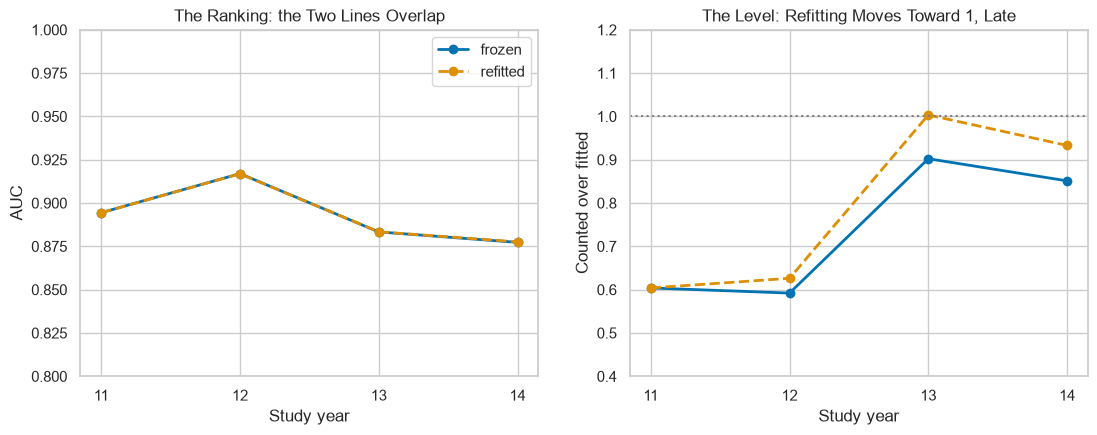

In [49]:
# left: the AUC; right: counted over fitted; frozen against refitted each year
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, style in [("frozen", "-"), ("refitted", "--")]:
    left.plot(refit.index, refit[f"AUC {name}"], marker="o", linestyle=style, linewidth=2, label=name)
    right.plot(refit.index, refit[f"ratio {name}"], marker="o", linestyle=style, linewidth=2, label=name)
right.axhline(1, color="gray", linestyle=":")
left.set(xticks=refit.index, ylim=(0.8, 1), xlabel="Study year", ylabel="AUC", title="The Ranking: the Two Lines Overlap")
right.set(xticks=refit.index, ylim=(0.4, 1.2), xlabel="Study year", ylabel="Counted over fitted", title="The Level: Refitting Moves Toward 1, Late")
left.legend()
plt.show()

The AUC barely moves: 0.9168, 0.8834 and 0.8776 refitted against 0.9170, 0.8833 and 0.8773 frozen.

The constant falls from -8.7757 to -9.2276 as the low years enter, and counted over fitted rises to 1.0034 and 0.9329 in years 13 and 14.

## Three Reports Side by Side

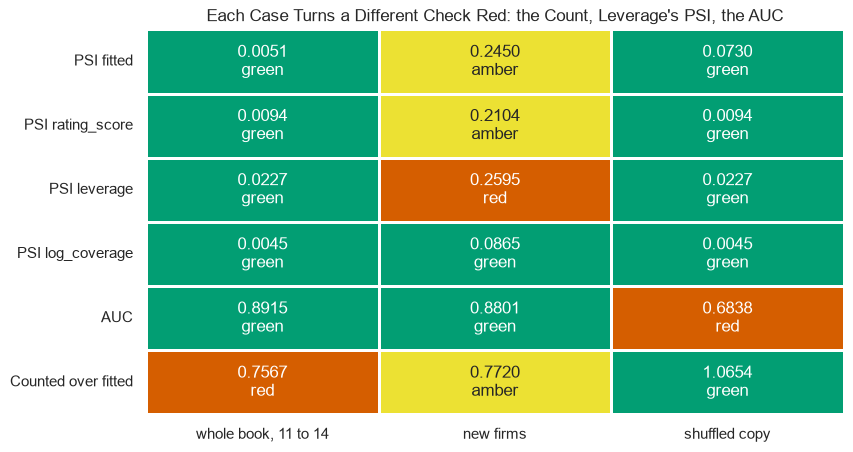

In [50]:
# the three cases' statuses and values in one grid
cases = {"whole book, 11 to 14": pooled_report, "new firms": new_report, "shuffled copy": shuffled_report}
case_codes = pd.DataFrame({name: (report["Status"] == "amber") * 1 + (report["Status"] == "red") * 2 for name, report in cases.items()})
case_labels = pd.DataFrame({name: report["Value"].map(lambda v: f"{v:.4f}") + "\n" + report["Status"] for name, report in cases.items()})
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(case_codes, cmap=list(STATUS_COLOURS.values()), vmin=0, vmax=2, annot=case_labels, fmt="", cbar=False, linewidths=1, linecolor="white", ax=ax)
ax.set(title="Each Case Turns a Different Check Red: the Count, Leverage's PSI, the AUC")
plt.show()

**Refitting moved the level toward the years just past and left the ranking where it was; each case broke a different check.**

> STORY: On April 17, 2026 the Federal Reserve issued SR 26-2, "Revised Guidance on Model Risk Management", which "supersedes and replaces SR letter 11-7".
> Section V of its attachment, "Model Validation and Monitoring", says outcomes analysis "compares model outputs to corresponding real-world outcomes", and lists "reports or analysis performed as part of ongoing monitoring" among its forms.
> It speaks of deviations "outside of the banking organization's established performance thresholds": each organization sets its own.
> Sources: Federal Reserve, SR 26-2, April 17, 2026, https://www.federalreserve.gov/supervisionreg/srletters/sr2602.htm, and its attachment, section V, https://www.federalreserve.gov/supervisionreg/srletters/sr2602a1.pdf (both read 2026-11-18)

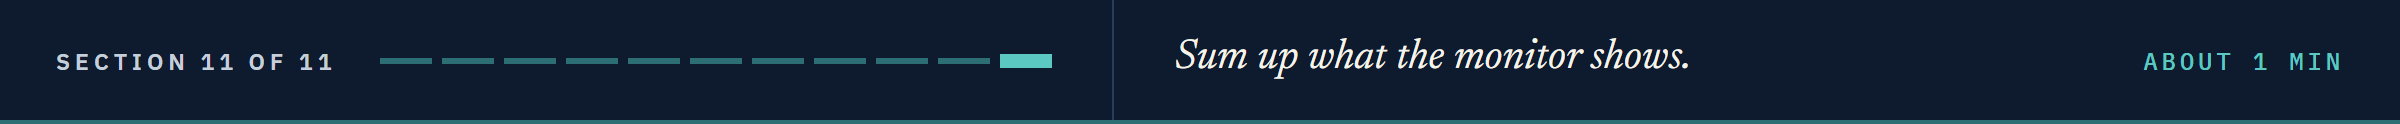

# Insights and Conclusion

The frozen model ranked every monitored year at an AUC of 0.88 to 0.92, above its in-sample 0.8693.

Over every firm-year the inputs moved little; the new firms' moved a lot, and the model still ranked them.

The level fell short of the model's count in every monitored year, outside its 95 percent Poisson range in years 11 and 12, for new and older firms alike.

In the shuffled copy every input check stayed green while the AUC fell to 0.68.

Refitted each year, the model followed the level late and ranked about as well.

**Watch inputs early and outcomes late, each against its own noise; neither alone says the model still works.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Freeze a model on reference years and score later years with it.
* Check a year's ranking and level, and set a count beside its Poisson range.
* Measure the drift of a score and its inputs against fixed reference edges, and flag unusual inputs.
* Separate the stock of firm-years from the flow of new firms.
* Write a monitoring report with stated bands and run it year by year, on a subgroup and on a planted copy.
* Compare a frozen model with one refitted each year.

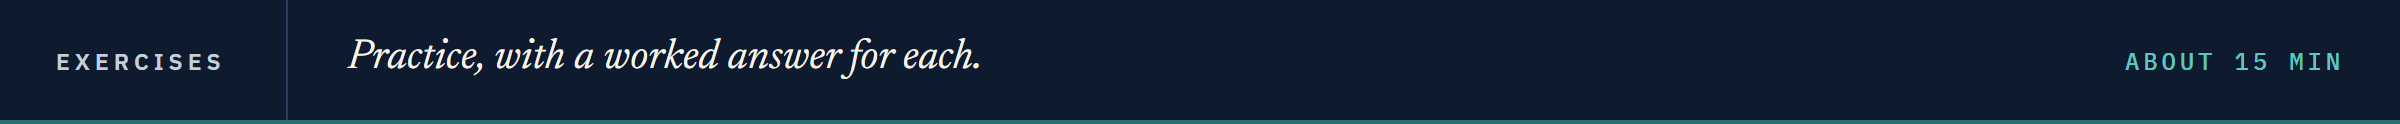

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [51]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The Older Firms in Year 12**

Q. Store counted over fitted in study year 12 for the firms that entered in study years 1 to 10 (`after_freeze` 0), under the frozen model, in `ex1_ratio`.

In [52]:
# your code here
ex1_ratio = ...

In [53]:
check("Exercise 1 the older firms' ratio in year 12", ex1_ratio, 0.6606472542556153)

Exercise 1 the older firms' ratio in year 12: not attempted yet


### Exercise 2

**Year 10's Upper Tail**

`stats.poisson.sf(k, mu)` is the chance of more than k.

Q. Store the Poisson chance of 45 or more defaults in reference year 10, given its fitted count, in `ex2_chance`.

In [54]:
# your code here
ex2_chance = ...

In [55]:
check("Exercise 2 the chance of 45 or more in year 10", ex2_chance, 0.014524960094311489)

Exercise 2 the chance of 45 or more in year 10: not attempted yet


### Exercise 3

**The AUC by Group**

Q. Write `auc_by_group(frame, group_col)`, with a one-line docstring, which returns the AUC of the `fitted` column against `default` within each group as a Series. Give the monitored years a `grade` column (IG for rating scores 1 to 10, HY for 11 to 18) and store HY's AUC in `ex3_hy_auc`.

In [56]:
# your code here
ex3_hy_auc = ...

In [57]:
check("Exercise 3 HY's AUC in the monitored years", ex3_hy_auc, 0.8078453500522466)

Exercise 3 HY's AUC in the monitored years: not attempted yet


### Exercise 4

**Two Years Pooled**

Q. Run `monitoring_report` on study years 11 and 12 pooled, and store the number of checks not green in `ex4_not_green`.

In [58]:
# your code here
ex4_not_green = ...

In [59]:
check("Exercise 4 checks not green in years 11 and 12", ex4_not_green, 1)

Exercise 4 checks not green in years 11 and 12: not attempted yet


### Exercise 5: AI check

**Scoring Later Years**

You asked an AI assistant for a function that fits the hazard on the early years and scores the later ones.
This came back.
Test it against its own docstring, then find the one bug.

In [60]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def score_years(firm_years, fit_end):
    """Fit the hazard on study years 1 to fit_end and score every later firm-year; the later defaults never touch the fit."""
    later = firm_years[firm_years["study_year"] > fit_end].copy()
    fit = sm.Logit(firm_years["default"], sm.add_constant(firm_years[FEATURES])).fit(disp=0)
    later["fitted"] = fit.predict(sm.add_constant(later[FEATURES]))
    return later

In [61]:
# the docstring's test: score 11 to 14, then again with every later default set to 0
scored = score_years(development, FIT_END)
zeroed = development.copy()
zeroed.loc[zeroed["study_year"] > FIT_END, "default"] = 0
print(f"Largest gap from the lesson's scores: {(scored['fitted'] - monitored['fitted']).abs().max():.2e} | counted over fitted {scored['default'].sum() / scored['fitted'].sum():.4f}, the lesson's {monitored['default'].sum() / monitored['fitted'].sum():.4f}")
print(f"Largest move in a score when only the later defaults change: {(score_years(zeroed, FIT_END)['fitted'] - scored['fitted']).abs().max():.1e}")

Largest gap from the lesson's scores: 2.75e-02 | counted over fitted 0.8409, the lesson's 0.7567
Largest move in a score when only the later defaults change: 1.9e-01


Q. Fix the one wrong line, rerun the test, and store the fixed function's counted over fitted on study years 11 to 14 in `ex5_ratio`.

In [62]:
# your code here
ex5_ratio = ...

In [63]:
check("Exercise 5 the fixed function's ratio", ex5_ratio, 0.7566589050953481)

Exercise 5 the fixed function's ratio: not attempted yet


## Congratulations!

You froze a hazard model on ten study years and watched four more with it, as a risk team would.
You learned which checks can run on a year's first day and which must wait for its end, and read each against its own noise.
You found a ranking that held while the level fell short, a drift the whole book hid for years, and a broken link that no input check could see.
Next, the capstone opens the held-out study years once, with this report among its tools.

[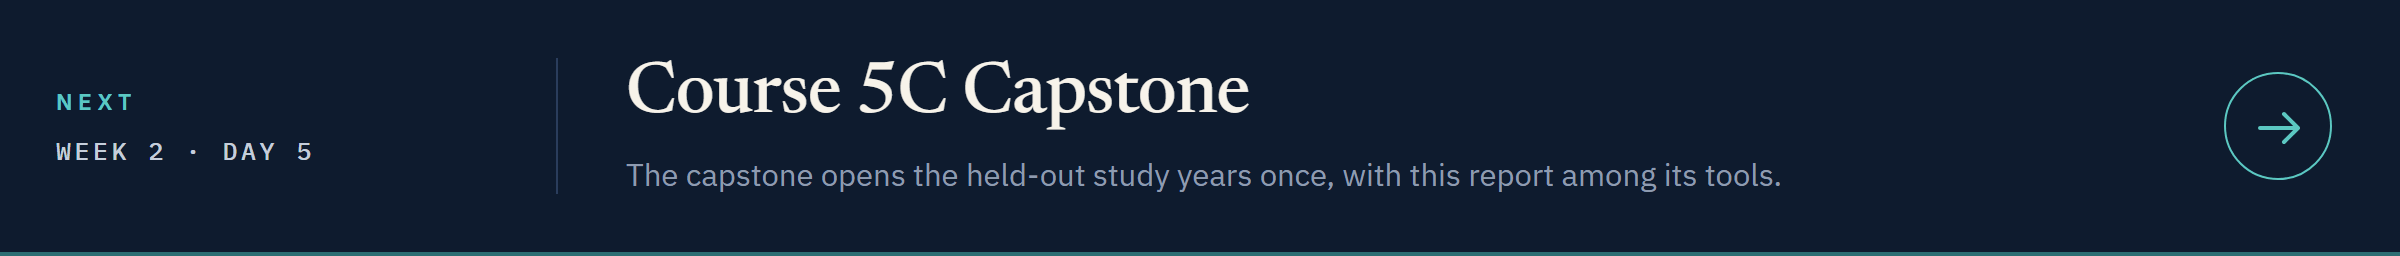](../day5/course5c_capstone.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day5/course5c_capstone.ipynb)